# Black Hole Aerodynamics

In this code, we want to simulate the aerodynamical effects in Dyson, et al. (2024) for a spinning orbiter. We use the formalism in Drummond and Hughes (2022) to compute the geodesics around a spinning orbiter. First, let us import the necessary packages.

In [1]:
#Packages for plotting.
import numpy as np #For general-purpose calculations.
from astropy import constants as const #For inserting astrophysical constants.
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
%matplotlib widget
from matplotlib import rcParams
import matplotlib.animation as animation
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Line3D

from matplotlib.patches import FancyArrowPatch
from mpl_toolkits.mplot3d import proj3d


#Packages for calculations such as numerical integration and interpolation.
from scipy import integrate
from scipy.integrate import solve_ivp, cumtrapz
from scipy.interpolate import interp1d
from scipy.optimize import root_scalar
from scipy.optimize import fsolve
from scipy.signal.windows import tukey, hann, boxcar, nuttall, blackman

# Packages to aid optimization.
import tqdm
import time
import os
import subprocess
import fileinput

#Specialized packages for computing the Kerr geodesics.
from few.trajectory.inspiral import EMRIInspiral
from few.utils.constants import MTSUN_SI, YRSID_SI, Pi
from few.utils.utility import (get_overlap,
                               get_mismatch,
                               get_fundamental_frequencies,
                               get_separatrix,
                               get_mu_at_t,
                               get_p_at_t,
                               get_kerr_geo_constants_of_motion, ELQ_to_pex, xI_to_Y, Y_to_xI)
from kerr_funcs import roots_z_equation, deriv_psi_t, deriv_chi_t, deriv_phi_t
from kerr_derivatives import dEdM, dQdM, dLzdM, dEda, dLzda, dQda 
import kerrgeopy as kg
from kerrgeopy.constants import constants_of_motion, apex_from_constants
from kerrgeopy.frequencies import *
from kerrgeopy.spacetime import *
from kerrgeopy.stable import *
from kerrgeopy.spinning_test import *
#from kerrgeopy.osculating_geodesics_funcs import *
from plot_formatting import plot_fading_line_3d, spherical_to_cartesian
from compute_actions import full_kerr_actions, QKO_derivatives 
from kerrgeopy.osculating_geodesics_funcs_test import *
#from spectral_decomposition import *
#from test_functions import *
from math import cos, pi
G = const.G.cgs.value 
c = const.c.cgs.value 
Msun = const.M_sun.cgs.value
one_year = YRSID_SI

In [2]:
# Orbit parameters
a = 0.0# Black hole spin
p0 = 8.1371      # Semi-latus rectum
e0 = 0.525      # Eccentricity
xI0 = 1.0    # Inclination parameter (cosθ)
qt0 = qr0 = qtheta0 = qphi0 = 0  # Initial phases
#orbit = kg.PlungingOrbit(a, 0.94, 0.1, 12, initial_phases=(qt0, qr0, qtheta0, qphi0))

In [3]:
ut_func, ur_func, utheta_func, uphi_func = orbit.four_velocity()
t_func, r_func, theta_func, phi_func = orbit.trajectory()

NameError: name 'orbit' is not defined

In [4]:
t_func(0), r_func(0), theta_func(0), phi_func(0)

NameError: name 't_func' is not defined

In [5]:
ut_func(0), ur_func(0), utheta_func(0), uphi_func(0)

NameError: name 'ut_func' is not defined

In [6]:
def check_orthonormality(a, r, theta, phi, e0, e1, e2, e3):
    spacetime = kg.KerrSpacetime(a=a, M=1)
    Kerr_cov = spacetime.metric(0, r, theta, phi)
    Kerr_contra = np.linalg.inv(Kerr_cov)
    
    # Convert covariant to contravariant
    def raise_index(vec):
        return np.einsum('ij,j->i', Kerr_contra, vec)
    
    e0_con = raise_index(e0)
    e1_con = raise_index(e1)
    e2_con = raise_index(e2)
    e3_con = raise_index(e3)
    
    # Check norms
    print("Norms:")
    print(f"e0·e0 = {np.dot(e0, e0_con):.16f} (should be -1)")
    print(f"e1·e1 = {np.dot(e1, e1_con):.16f} (should be 1)")
    print(f"e2·e2 = {np.dot(e2, e2_con):.16f} (should be 1)")
    print(f"e3·e3 = {np.dot(e3, e3_con):.16f} (should be 1)")
    
    # Check orthogonality
    print("\nOrthogonality:")
    print(f"e0·e1 = {np.dot(e0, e1_con):.16e} (should be 0)")
    print(f"e0·e2 = {np.dot(e0, e2_con):.16e} (should be 0)")
    print(f"e0·e3 = {np.dot(e0, e3_con):.16e} (should be 0)")
    print(f"e1·e2 = {np.dot(e1, e2_con):.16e} (should be 0)")
    print(f"e1·e3 = {np.dot(e1, e3_con):.16e} (should be 0)")
    print(f"e2·e3 = {np.dot(e2, e3_con):.16e} (should be 0)")

# Usage example
a, p0, e0, xI0 = 0.999, 3, 0.65, np.cos(np.pi/4)
qr0, qz0 = np.pi/3, np.pi/2 
e0_vec, e1_vec, e2_vec, e3_vec = Marck_tetrad(3, a, p0, e0, xI0, qr0=qr0, qz0=qz0)
sinI = np.sqrt(1 - xI0**2)

constants = constants_of_motion(a, p0, e0, xI0)
radial_roots = stable_radial_roots(a, p0, e0, xI0)
polar_roots = stable_polar_roots(a, p0, e0, xI0)
r, _ ,_ ,  = radial_solutions(a, constants, radial_roots)
r = r(qr0)
theta, _, _, = polar_solutions(a, constants, polar_roots)
theta = theta(qz0)

check_orthonormality(a, r, theta, 0, e0_vec, e1_vec, e2_vec, e3_vec)

Norms:
e0·e0 = -1.0000000000000004 (should be -1)
e1·e1 = 0.9999999999999997 (should be 1)
e2·e2 = 0.9999999999999991 (should be 1)
e3·e3 = 1.0000000000000004 (should be 1)

Orthogonality:
e0·e1 = -1.6653345369377348e-16 (should be 0)
e0·e2 = 1.3322676295501878e-15 (should be 0)
e0·e3 = -4.4408920985006262e-16 (should be 0)
e1·e2 = 1.6653345369377348e-16 (should be 0)
e1·e3 = -5.5511151231257827e-17 (should be 0)
e2·e3 = 3.3306690738754696e-16 (should be 0)


In [7]:
def verify_spin_condition(lam, q, a, p, e, x, s, phi_s, theta_s, qr0=0, qz0=0, qpsi0=0):
    """
    Verify S^{αβ} p_α = 0 for given parameters
    
    Returns:
        condition (np.array): Vector S^{αβ} p_α for β=0,1,2,3
        norm (float): Euclidean norm of the condition vector
    """
    # Get spin tensor (contravariant)
    S_contra = spin_tensor(lam, q, a, p, e, x, s, phi_s, theta_s, qr0, qz0, qpsi0)
    
    # Get geodesic 4-velocity u^α (contravariant)
    orbit = StableOrbit(a, p, e, x)
    u_t, u_r, u_theta, u_phi = orbit.four_velocity()
    u_contra = np.array([
        u_t(lam),
        u_r(lam),
        u_theta(lam),
        u_phi(lam)
    ])
    
    # Get metric at current position
    constants = constants_of_motion(a, p, e, x)
    r, t_r, phi_r = radial_solutions(a, constants, stable_radial_roots(a, p, e, x))
    theta, t_theta, phi_theta = polar_solutions(a, constants, stable_polar_roots(a, p, e, x))
    r = r(qr0)
    theta = theta(qz0)  # Fixed: changed qr0 to qz0 for polar angle
    g_cov = KerrSpacetime(a=a, M=1).metric(0, r, theta, 0)
    
    # Compute p_α = g_{αβ} p^β (covariant momentum)
    p_cov = g_cov @ u_contra  # Matrix multiplication
    
    # Compute contraction: S^{αβ} p_α for each β using ASCII indices
    condition = np.einsum('ij,i->j', S_contra, p_cov)  # Fixed: replaced Greek chars
    
    return condition, np.linalg.norm(condition)
# Example usage
if __name__ == "__main__":
    # Sample parameters
    params = {
        'lam': 0.0,
        'q': 0.01,
        'a': 0.9,
        'p': 10.0,
        'e': 0.5,
        'x': np.cos(np.pi/4),
        's': 0.1,
        'phi_s': 0.0,
        'theta_s': np.pi/3,
        'qr0': np.pi/4,
        'qz0': np.pi/3
    }
    
    condition, norm = verify_spin_condition(**params)
    print(f"Contraction vector: {condition}")
    print(f"Norm: {norm:.3e} (should be near machine zero)")

Contraction vector: [ 0.00000000e+00 -3.33066907e-16 -1.73472348e-18  1.29246971e-26]
Norm: 3.331e-16 (should be near machine zero)


In [8]:
def test_killing_derivatives_schwarzschild():
    """Test Killing vector derivatives in Schwarzschild spacetime (a=0)"""
    r = 10.0  # Radial coordinate
    theta = np.pi/2  # Equatorial plane
    a = 0.0  # Schwarzschild
    
    cov_t, cov_phi = killing_vector_derivatives(r, theta, a)
    
    # Analytical expressions for Schwarzschild:
    # ξ_t = (1 - 2M/r) for covariant time Killing vector
    # Covariant derivative should be:
    #   ∇_r ξ_t = M/r^2
    #   ∇_t ξ_r = -M/r^2 (by antisymmetry)
    M = 1
    expected_dt_dr = M / r**2
    
    # Check time Killing vector derivatives
    print("Schwarzschild time Killing vector derivative test:")
    print(f"Computed ∇_r ξ_t: {cov_t[0,1]:.6e}")
    print(f"Expected ∇_r ξ_t: {expected_dt_dr:.6e}")
    print(f"Computed ∇_t ξ_r: {cov_t[1,0]:.6e}")
    print(f"Expected ∇_t ξ_r: {-expected_dt_dr:.6e}")
    
    # Check azimuthal Killing vector derivatives
    # In Schwarzschild equatorial: ∇_θ ξ_φ = -r^2 sinθ cosθ
    expected_dphi_dtheta = -r**2 * np.sin(theta) * np.cos(theta)
    print("\nAzimuthal Killing vector derivative test:")
    print(f"Computed ∇_θ ξ_φ: {cov_phi[2,3]:.6e}")
    print(f"Expected ∇_θ ξ_φ: {expected_dphi_dtheta:.6e}")

test_killing_derivatives_schwarzschild()

Schwarzschild time Killing vector derivative test:
Computed ∇_r ξ_t: -1.000000e-02
Expected ∇_r ξ_t: 1.000000e-02
Computed ∇_t ξ_r: 1.000000e-02
Expected ∇_t ξ_r: -1.000000e-02

Azimuthal Killing vector derivative test:
Computed ∇_θ ξ_φ: -6.123234e-15
Expected ∇_θ ξ_φ: -6.123234e-15


In [9]:
def validate_spin_tensor():
    """Check spin tensor properties at correct orbital position"""
    params = {
        'lam': 0.0,
        'q': 1e-4,
        'a': 0.9,
        'p': 10.0,
        'e': 0.5,
        'x': np.cos(np.pi/4),
        's': 0.01,
        'phi_s': np.pi/4,
        'theta_s': np.pi/3,
        'qr0': np.pi/4,
        'qz0': np.pi/3
    }
    
    # Compute position at λ=0
    orbit = StableOrbit(params['a'], params['p'], params['e'], params['x'])
    constants = constants_of_motion(params['a'], params['p'], params['e'], params['x'])
    
    # Get radial and polar position functions
    r_func, _, _ = radial_solutions(params['a'], constants, 
                                  stable_radial_roots(params['a'], params['p'], params['e'], params['x']))
    theta_func, _, _ = polar_solutions(params['a'], constants, 
                                     stable_polar_roots(params['a'], params['p'], params['e'], params['x']))
    
    # Compute actual position at λ=0 with initial phases
    r = r_func(params['qr0'])
    theta = theta_func(params['qz0'])
    
    # Compute spin tensor at correct position
    S_contra = spin_tensor(**params)
    
    # Get 4-velocity at λ=0
    u_t, u_r, u_theta, u_phi = orbit.four_velocity()
    u_contra = np.array([
        u_t(params['lam']),
        u_r(params['lam']),
        u_theta(params['lam']),
        u_phi(params['lam'])
    ])
    
    # Verify orthogonality
    g_cov = KerrSpacetime(a=params['a']).metric(0, r, theta, 0)
    p_cov = g_cov @ u_contra
    contraction = np.einsum('ij,i->j', S_contra, p_cov)
    norm = np.linalg.norm(contraction)
    
    print(f"Position: r={r:.4f}, θ={theta:.4f}")
    print(f"Spin tensor orthogonality check: {norm:.2e} (should be small)")
    return norm

# Run the validation
norm = validate_spin_tensor()

Position: r=7.3187, θ=1.2093
Spin tensor orthogonality check: 5.55e-17 (should be small)


In [10]:
def check_conservation():
    # Initialize parameters
    a = 0.9; p = 8; e = 0.7; x = 0.6; s = 0.1
    phi_s = 0; theta_s = np.pi/4; q = 0.01
    lam_vals = np.linspace(0, 100, 1000)
    
    # Storage
    E_corr = []; J_corr = []
    
    for lam in lam_vals:
        corr_E, corr_J = spin_correction_terms(lam, q, a, p, e, x, s, phi_s, theta_s, 0, 0)
        E_corr.append(corr_E)
        J_corr.append(corr_J)
    
    # Plot results
    plt.figure(figsize=(12, 5))
    plt.subplot(121)
    plt.plot(lam_vals, E_corr)
    plt.title("Energy Correction")
    plt.subplot(122)
    plt.plot(lam_vals, J_corr)
    plt.title("Angular Momentum Correction")
    plt.show()

In [11]:
s, q = 0.05, 1e-5

In [12]:
# Test constancy of corrections
lambdas = np.linspace(0, 50, 500)
corrections_E = []
corrections_Jz = []

for lam in lambdas:
    E_corr, Jz_corr = spin_correction_terms(
        lam, q, a, p0, e0, xI0, s, np.pi/4, np.pi/3
    )
    corrections_E.append(E_corr)
    corrections_Jz.append(Jz_corr)

# Should be constant (plot to verify)
import matplotlib.pyplot as plt
plt.figure()
plt.plot(lambdas, corrections_E, label='$\delta E$')
#plt.plot(lambdas, corrections_Jz, label='$\delta J_z$')
plt.legend(); plt.ylabel("Value"); plt.xlabel("$\lambda$");

NameError: name 'compute_position' is not defined

In [13]:
a, p0, e0, xI0 = 0.95, 6, 0.01, np.cos(np.pi/4)
constants = constants_of_motion(a, p0, e0, xI0)
E, L, Q = constants

In [14]:
constants

(0.9254762290656846, 2.051132291910822, 4.271895233351596)

In [15]:
a, p0, e0, xI0 = 0.95, 6, 0.5, np.cos(np.pi/4)
orbit_spin = SpinningOrbit(a, p0, e0, xI0, 1e-7, np.pi/4, np.pi/4, M=1, mu=1e-7)
t, r, theta, phi = orbit.trajectory()


=== DEBUGGING SPINNING CONSTANTS ===
Position: r=4.0, theta=0.7853981633974484

Spin tensor S_mu_nu (specific, should be O(s)=1e-07):
Max abs value: 7.259266325526012e-07

Killing vectors (covariant):
ξ_t = [-0.51371476  0.          0.         -0.23098549]
ξ_phi = [-0.23098549  0.          0.          8.56096811]

Killing vector derivatives:
∇ξ_t (max abs): 0.23732131000383055
∇ξ_phi (max abs): 8.673695728778679
Four-velocity norm: -0.9999999999999953 (should be -1)

Geodesic constants from Killing vectors: E=0.9426017150297081, L=2.0904240577697024
Geodesic constants from orbital params: E=0.9426017150297081, L=2.090424057769703

Energy: geodesic=0.942601715030, spin_correction=-3.185807e-09, total=0.942601711844
Angular momentum: geodesic=2.090424057770, spin_correction=-1.296561e-06, total=2.090422761209

Geodesic Carter constant K from orbital params: 5.848099328238938
Geodesic K from Killing tensor: 5.848099328238935

Killing-Yano tensor Y (max abs): 47.80748947602248
∇Y (max abs

NameError: name 'orbit' is not defined

In [23]:
orbit_spin = SpinningOrbit(a, p0, e0, xI0, 5e-3, np.pi/4, np.pi/4, M=1, mu=1e-5)
orbit = StableOrbit(a, p0, e0, xI0, M=1, mu=1e-5)
t, r, theta, phi = orbit.trajectory()
time = np.linspace(0, 30, 2500)  # Create Mino time grid
# For spinning orbit: use compute_trajectory() method
t_spin, r_spin, theta_spin, phi_spin = orbit_spin.compute_trajectory(time)


=== DEBUGGING SPINNING CONSTANTS ===
Position: r=4.0, theta=0.7853981633974484

Spin tensor S_mu_nu (specific, should be O(s)=0.005):
Max abs value: 0.03629633162763007

Killing vectors (covariant):
ξ_t = [-0.51371476  0.          0.         -0.23098549]
ξ_phi = [-0.23098549  0.          0.          8.56096811]

Killing vector derivatives:
∇ξ_t (max abs): 0.23732131000383055
∇ξ_phi (max abs): 8.673695728778679
Four-velocity norm: -0.9999999999999953 (should be -1)

Geodesic constants from Killing vectors: E=0.9426017150297081, L=2.0904240577697024
Geodesic constants from orbital params: E=0.9426017150297081, L=2.090424057769703

Energy: geodesic=0.942601715030, spin_correction=-1.592903e-04, total=0.942442424696
Angular momentum: geodesic=2.090424057770, spin_correction=-6.482804e-02, total=2.025596014205

Geodesic Carter constant K from orbital params: 5.848099328238938
Geodesic K from Killing tensor: 5.848099328238935

Killing-Yano tensor Y (max abs): 47.80748947602248
∇Y (max abs):

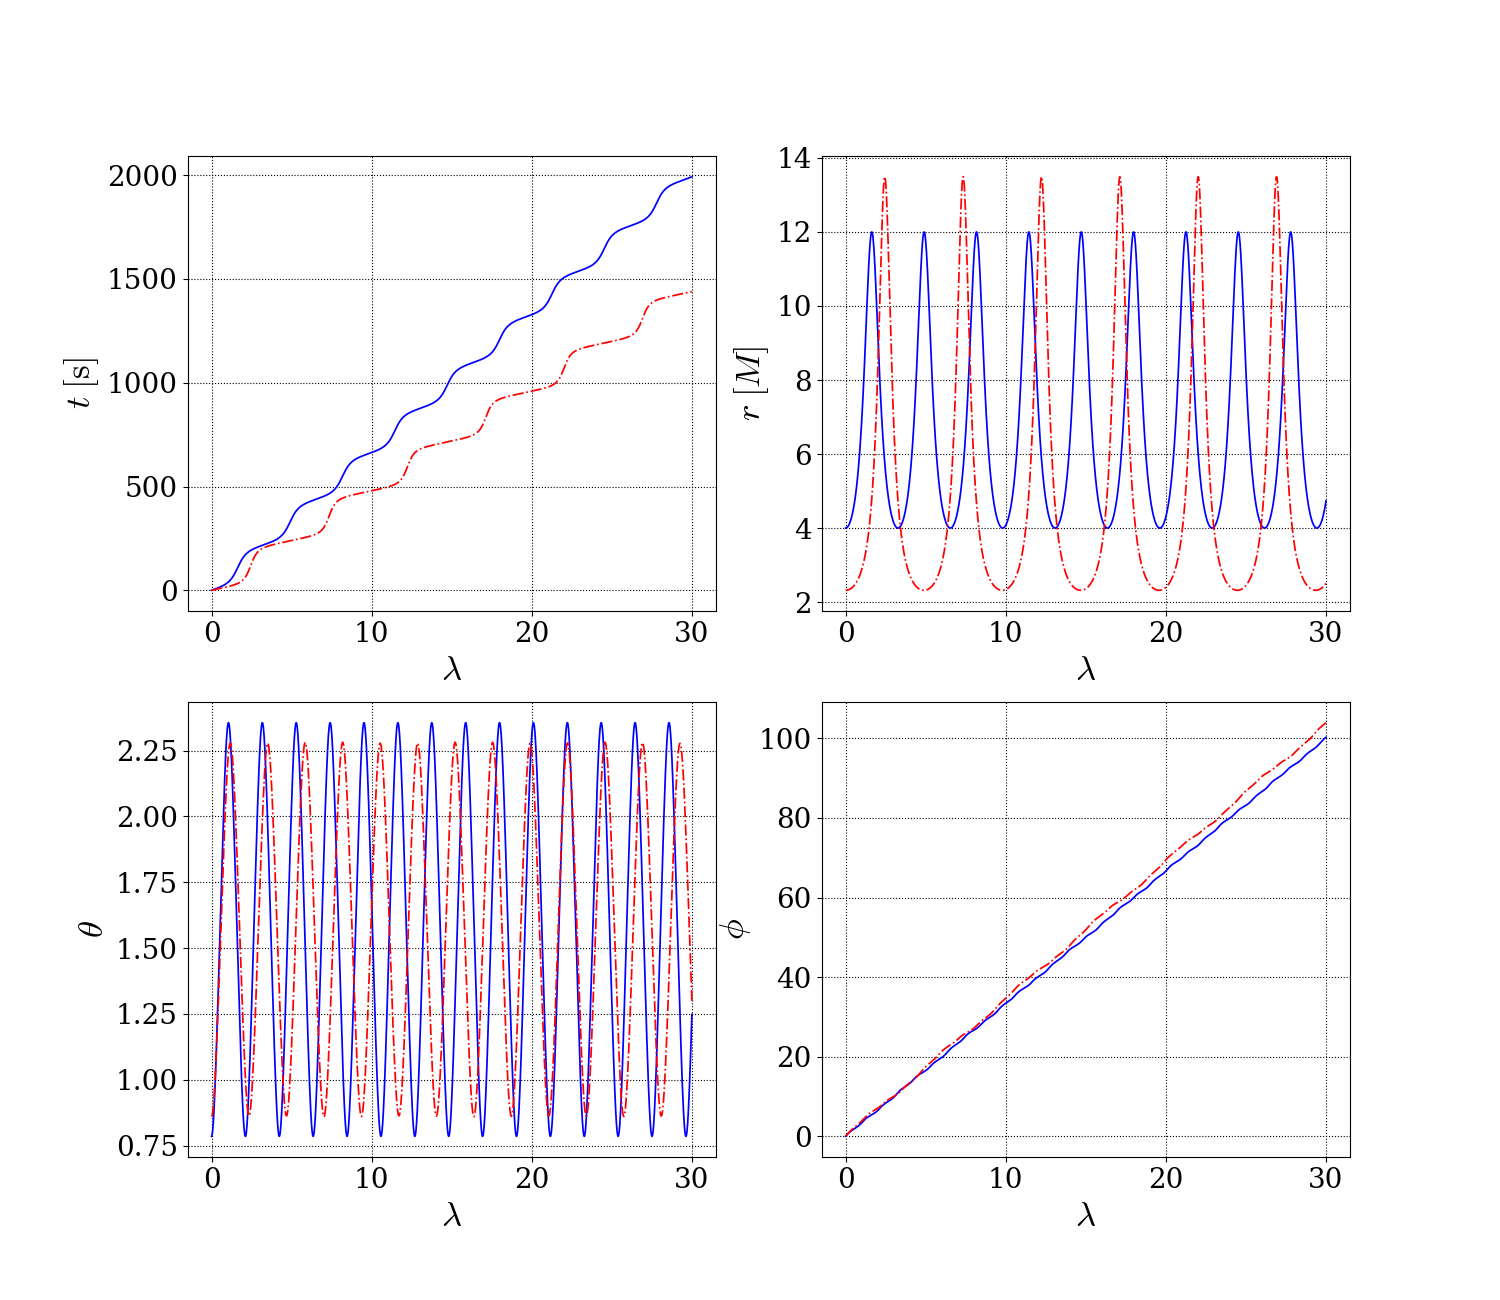

In [24]:
plt.figure(figsize=(15,13))
plt.rc('xtick', labelsize=20)   # fontsize of the tick labels
plt.rc('ytick', labelsize=20)   # fontsize of the tick labels

plt.subplot(2,2,1)
plt.plot(time, t(time),"b-", linewidth = 1.25)
plt.plot(time, t_spin,"r-.", linewidth = 1.25)
plt.xlabel("$\lambda$",fontsize=25)
plt.ylabel(r"$t\;[\mathrm{s}]$",fontsize=25)
plt.grid(linestyle=":",color="black")

plt.subplot(2,2,2)
plt.plot(time, r(time),"b-", linewidth = 1.25)
plt.plot(time, r_spin,"r-.", linewidth = 1.25)
plt.xlabel("$\lambda$",fontsize=25)
plt.ylabel("$r\;[M]$",fontsize=25)
plt.grid(linestyle=":",color="black")

plt.subplot(2,2,3)
plt.plot(time, theta(time),"b-", linewidth = 1.25)
plt.plot(time, theta_spin,"r-.", linewidth = 1.25)
plt.xlabel("$\lambda$",fontsize=25)
plt.ylabel(r"$\theta$",fontsize=25)
plt.grid(linestyle=":",color="black")

plt.subplot(2,2,4)
plt.plot(time, phi(time),"b-", linewidth = 1.25)
plt.plot(time, phi_spin,"r-.", linewidth = 1.25)
plt.xlabel("$\lambda$",fontsize=25)
plt.ylabel(r"$\phi$",fontsize=25)
plt.grid(linestyle=":",color="black")
plt.savefig("Trajectory_spin_comparison.pdf")
plt.show()


In [25]:
Sx, Sy, Sz = [], [], []
S_vec = []
q = 1e-5
qpsi = 0.0
for i in range(len(time)):
    #e0_vec.append(Marck_tetrad(time[i], a, p0, e0, xI0, qr0=qr0, qz0=qz0, qpsi0 = qpsi)[0])
    #e1_vec.append(Marck_tetrad(time[i], a, p0, e0, xI0, qr0=qr0, qz0=qz0, qpsi0 = qpsi)[1])
    #e2_vec.append(Marck_tetrad(time[i], a, p0, e0, xI0, qr0=qr0, qz0=qz0, qpsi0 = qpsi)[2])
    #e3_vec.append(Marck_tetrad(time[i], a, p0, e0, xI0, qr0=qr0, qz0=qz0, qpsi0 = qpsi)[3])
    #qpsi.append(psi_phase(time[i], a, p0, e0, xI0, qr0=qr0, qz0=qz0, qpsi0 = qpsi[-1]))
    S_vec.append(spin_vector(time[i], q, a, p0, e0, xI0, 0.05, np.pi/4, np.pi/4,  qr0=qr0, qz0=qz0, qpsi0 = qpsi))
    Sx_j, Sy_j, Sz_j = spherical_to_cartesian(S_vec[i][1], S_vec[i][2], S_vec[i][3])
    Sx.append(5*Sx_j)
    Sy.append(5*Sy_j)
    Sz.append(5*Sz_j)

In [67]:
spin_vector(time, q, a, p0, e0, xI0, 0.5, np.pi/4, np.pi/4,  qr0=qr0, qz0=qz0, qpsi0 = qpsi)

NameError: name 'qz0' is not defined

In [68]:
Sx = np.array(Sx)
Sy = np.array(Sy)
Sz = np.array(Sz)

In [69]:
x, y, z = spherical_to_cartesian(np.array(r(time)), 
                                np.array(theta(time)), 
                                np.array(phi(time)))

x_s, y_s, z_s = spherical_to_cartesian(r_spin, theta_spin, phi_spin)

In [73]:
import kerrgeopy as kg
from matplotlib.colors import LightSource
from math import cos, pi
orbit = kg.StableOrbit(a, p0, e0, xI0)

x, y, z = spherical_to_cartesian(np.array(r(time)), 
                                np.array(theta(time)), 
                                np.array(phi(time)))

x_s, y_s, z_s = spherical_to_cartesian(r_spin, theta_spin, phi_spin)


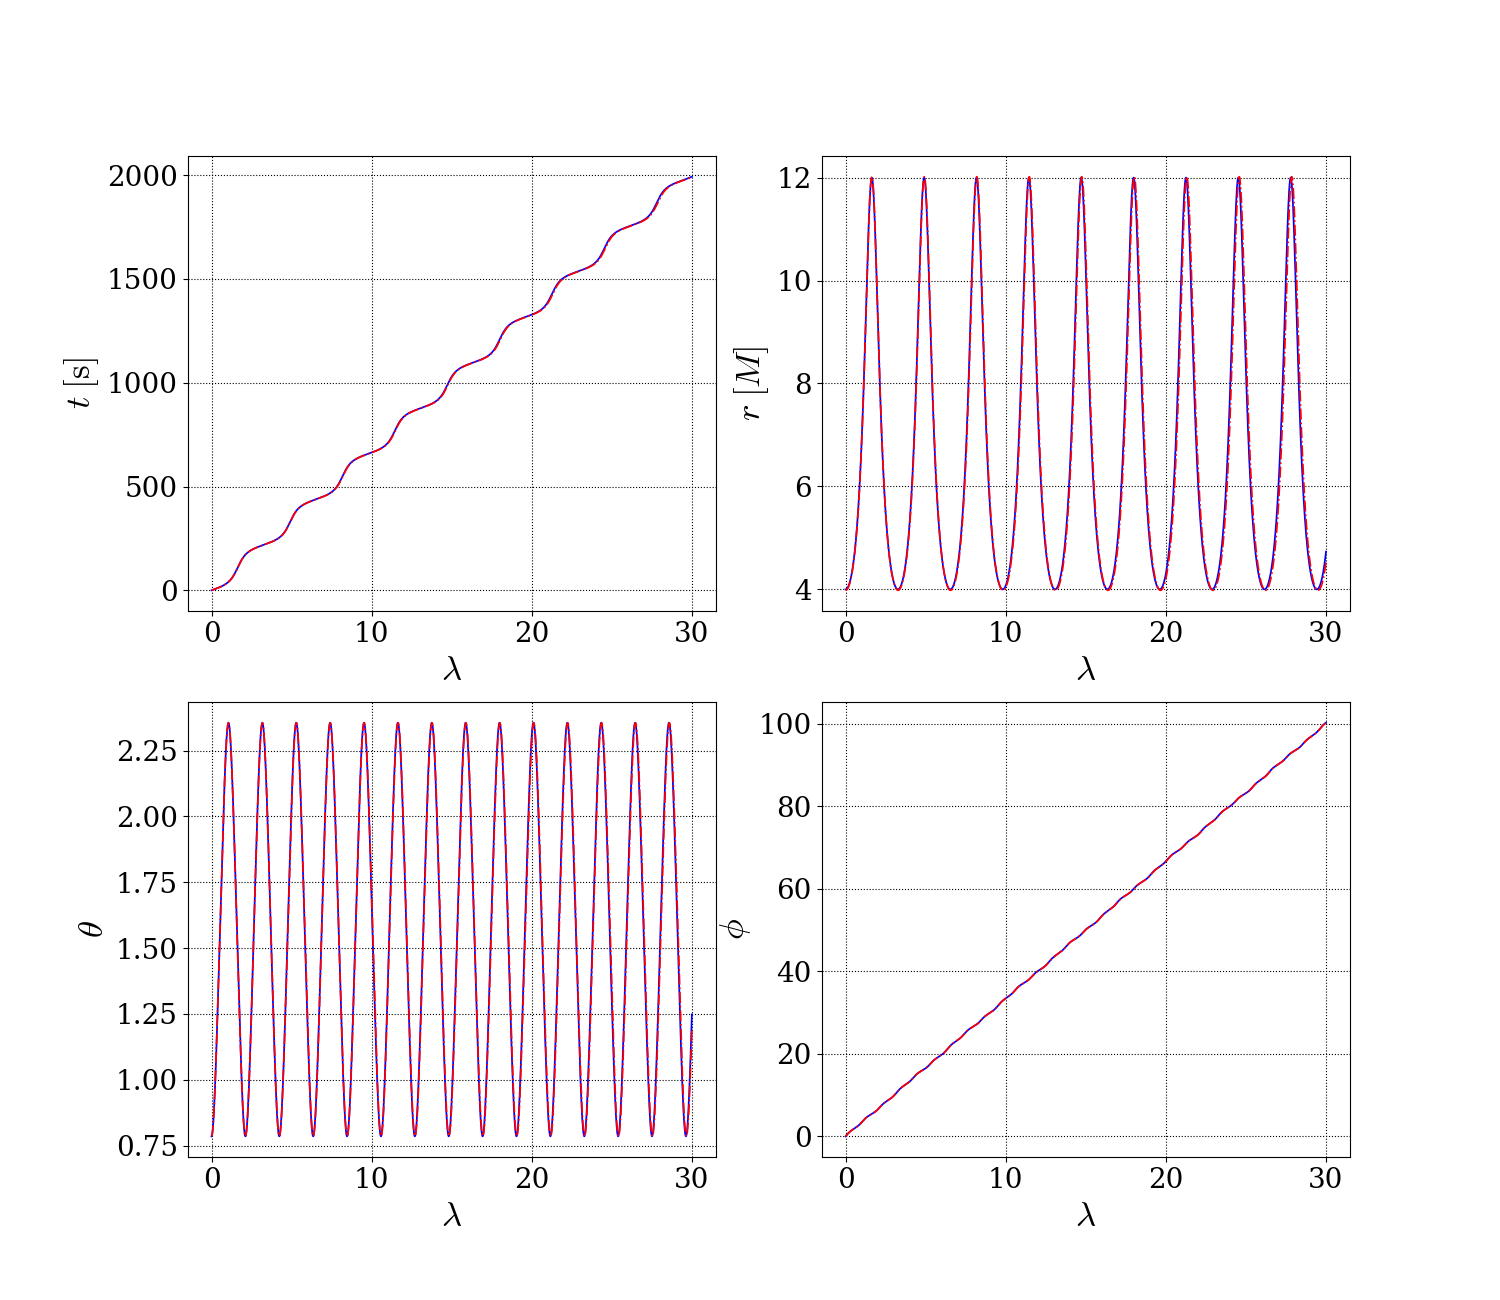

In [74]:
plt.figure(figsize=(15,13))
plt.rc('xtick', labelsize=20)   # fontsize of the tick labels
plt.rc('ytick', labelsize=20)   # fontsize of the tick labels

plt.subplot(2,2,1)
plt.plot(time, t(time),"b-", linewidth = 1.25)
plt.plot(time, t_spin,"r-.", linewidth = 1.25)
plt.xlabel("$\lambda$",fontsize=25)
plt.ylabel(r"$t\;[\mathrm{s}]$",fontsize=25)
plt.grid(linestyle=":",color="black")

plt.subplot(2,2,2)
plt.plot(time, r(time),"b-", linewidth = 1.25)
plt.plot(time, r_spin,"r-.", linewidth = 1.25)
plt.xlabel("$\lambda$",fontsize=25)
plt.ylabel("$r\;[M]$",fontsize=25)
plt.grid(linestyle=":",color="black")

plt.subplot(2,2,3)
plt.plot(time, theta(time),"b-", linewidth = 1.25)
plt.plot(time, theta_spin,"r-.", linewidth = 1.25)
plt.xlabel("$\lambda$",fontsize=25)
plt.ylabel(r"$\theta$",fontsize=25)
plt.grid(linestyle=":",color="black")

plt.subplot(2,2,4)
plt.plot(time, phi(time),"b-", linewidth = 1.25)
plt.plot(time, phi_spin,"r-.", linewidth = 1.25)
plt.xlabel("$\lambda$",fontsize=25)
plt.ylabel(r"$\phi$",fontsize=25)
plt.grid(linestyle=":",color="black")
plt.savefig("Trajectory_spin_comparison.pdf")
plt.show()


In [92]:
orbit = StableOrbit(a, p0, e0, xI0, M=1, mu=1e-5)
time = np.linspace(0, 25, 1250)  # Create Mino time grid
# For spinning orbit: use compute_trajectory() method
t_spin_array = []
r_spin_array = []
theta_spin_array = []
phi_spin_array = []
s_array = [5e-3, 1e-4, 1e-5]
for i in s_array:
    orbit_spin = SpinningOrbit(a, p0, e0, xI0, i, np.pi/4, np.pi/4, M=1, mu=1e-5)
    t_spin, r_spin, theta_spin, phi_spin = orbit_spin.compute_trajectory(time)
    t_spin_array.append(t_spin)
    r_spin_array.append(r_spin)
    theta_spin_array.append(theta_spin)
    phi_spin_array.append(phi_spin)



=== DEBUGGING SPINNING CONSTANTS ===
Position: r=4.0, theta=0.7853981633974484

Spin tensor S_mu_nu (specific, should be O(s)=0.005):
Max abs value: 0.03629633162763007

Killing vectors (covariant):
ξ_t = [-0.51371476  0.          0.         -0.23098549]
ξ_phi = [-0.23098549  0.          0.          8.56096811]

Killing vector derivatives:
∇ξ_t (max abs): 0.23732131000383055
∇ξ_phi (max abs): 8.673695728778679
Four-velocity norm: -0.9999999999999953 (should be -1)

Geodesic constants from Killing vectors: E=0.9426017150297081, L=2.0904240577697024
Geodesic constants from orbital params: E=0.9426017150297081, L=2.090424057769703

Energy: geodesic=0.942601715030, spin_correction=-1.592903e-04, total=0.942442424696
Angular momentum: geodesic=2.090424057770, spin_correction=-6.482804e-02, total=2.025596014205

Geodesic Carter constant K from orbital params: 5.848099328238938
Geodesic K from Killing tensor: 5.848099328238935

Killing-Yano tensor Y (max abs): 47.80748947602248
∇Y (max abs):

/tmp/ipykernel_14479/2794257330.py:8: RuntimeWarning: divide by zero encountered in divide
  plt.semilogy(time, np.abs(t_spin_array[0] - t(time))/t(time),"k-.", linewidth = 1.25, label = r'$s=0.01$')
/tmp/ipykernel_14479/2794257330.py:9: RuntimeWarning: divide by zero encountered in divide
  plt.semilogy(time, np.abs(t_spin_array[1] - t(time))/t(time),"b-", linewidth = 1.25, label = r'$s=0.001$')
/tmp/ipykernel_14479/2794257330.py:10: RuntimeWarning: divide by zero encountered in divide
  plt.semilogy(time, np.abs(t_spin_array[2] - t(time))/t(time),"r--", linewidth = 1.25, label = r'$s=0.0001$')
/tmp/ipykernel_14479/2794257330.py:36: RuntimeWarning: divide by zero encountered in divide
  plt.semilogy(time, np.abs(phi_spin_array[0] - phi(time))/phi(time),"k-.", linewidth = 1.25)
/tmp/ipykernel_14479/2794257330.py:37: RuntimeWarning: divide by zero encountered in divide
  plt.semilogy(time, np.abs(phi_spin_array[1] - phi(time))/phi(time),"b-", linewidth = 1.25)
/tmp/ipykernel_14479/27942

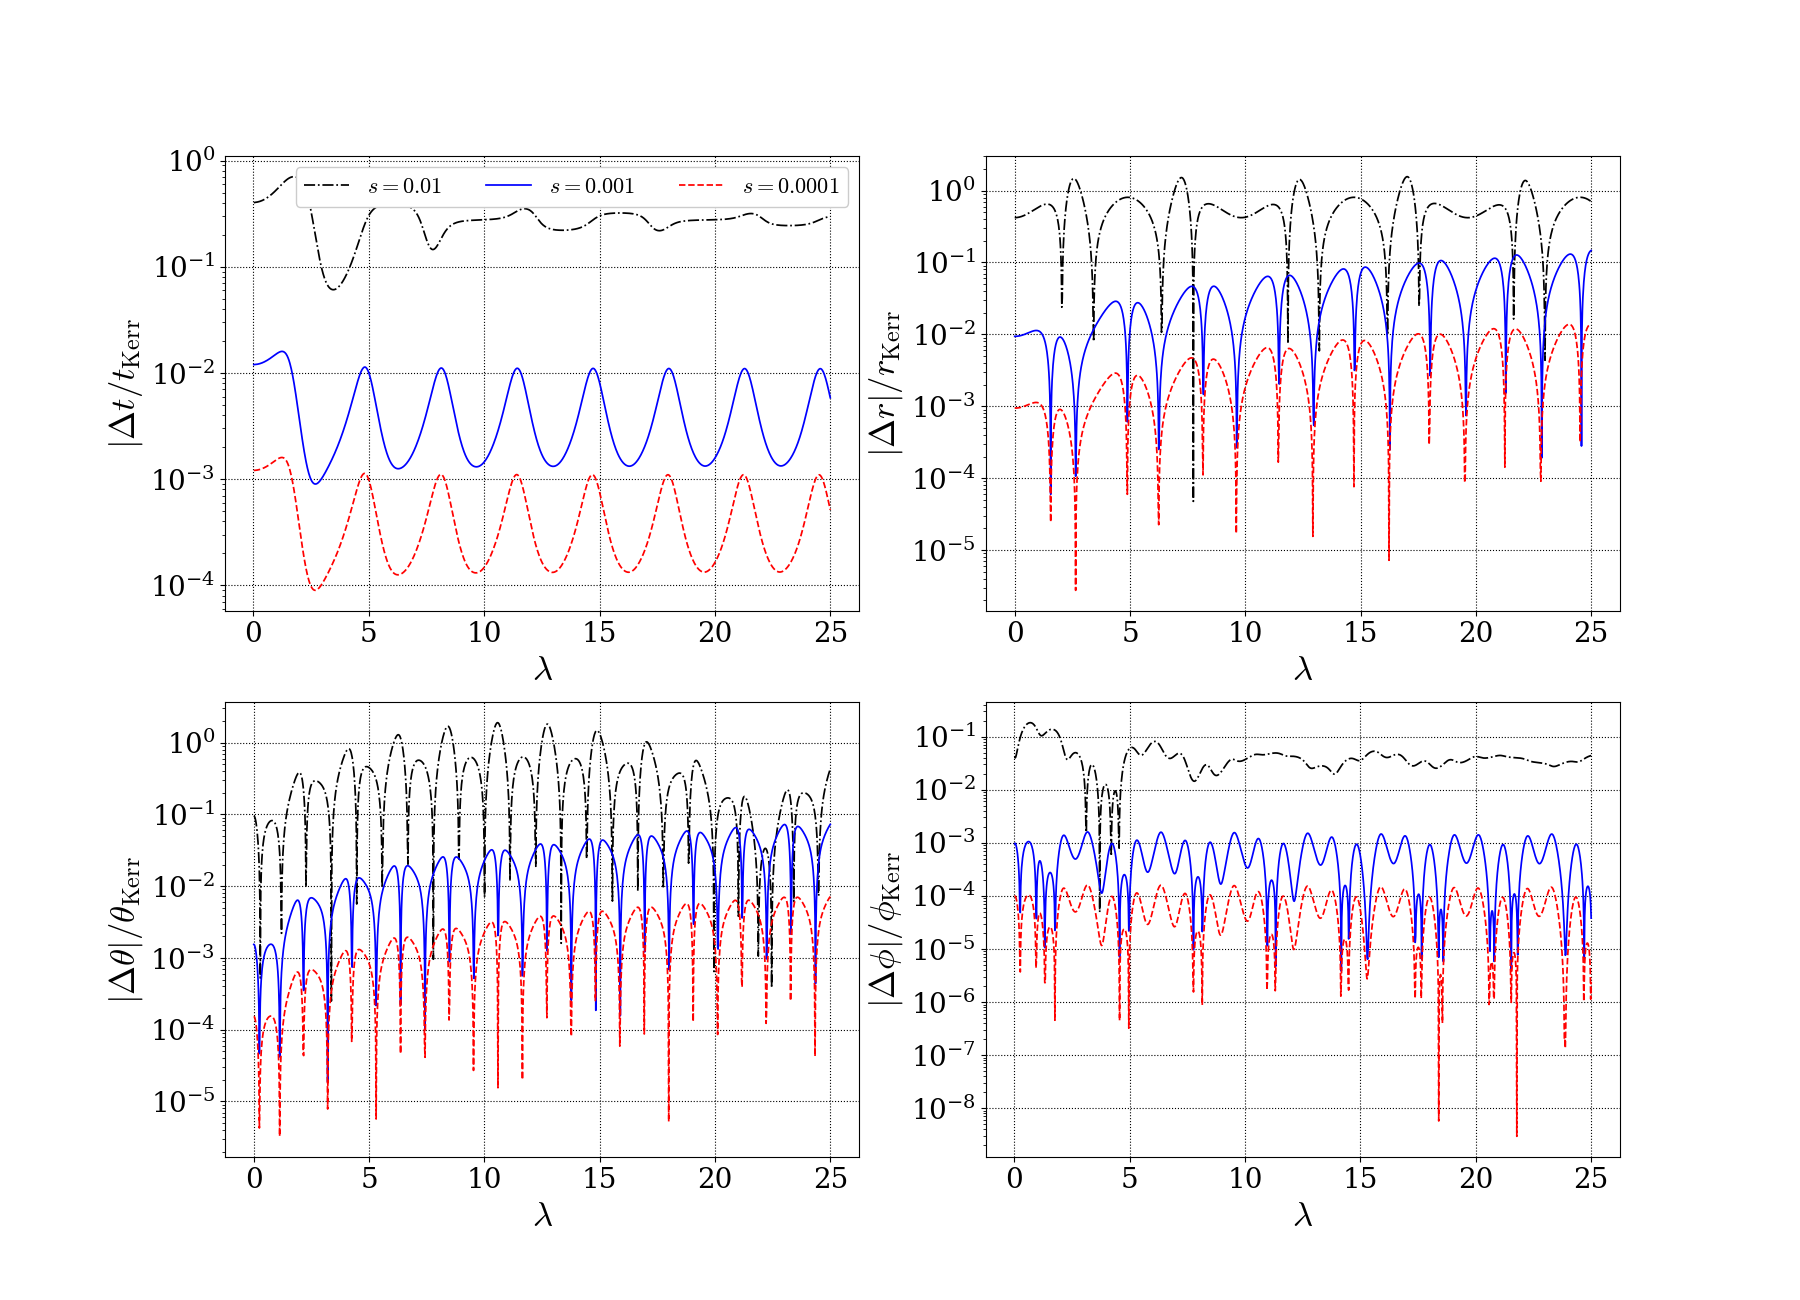

In [93]:
plt.figure(figsize=(18,13))
plt.rc('xtick', labelsize=20)   # fontsize of the tick labels
plt.rc('ytick', labelsize=20)   # fontsize of the tick labels
#plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

plt.subplot(2,2,1)
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
plt.semilogy(time, np.abs(t_spin_array[0] - t(time))/t(time),"k-.", linewidth = 1.25, label = r'$s=0.01$')
plt.semilogy(time, np.abs(t_spin_array[1] - t(time))/t(time),"b-", linewidth = 1.25, label = r'$s=0.001$')
plt.semilogy(time, np.abs(t_spin_array[2] - t(time))/t(time),"r--", linewidth = 1.25, label = r'$s=0.0001$')
plt.xlabel("$\lambda$",fontsize=25)
plt.ylabel(r"$|\Delta t/t_{\mathrm{Kerr}}$",fontsize=25)
plt.legend(fontsize=16, ncols=3, framealpha=1)
plt.grid(linestyle=":",color="black")

plt.subplot(2,2,2)
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
plt.semilogy(time, np.abs(r_spin_array[0] - r(time))/r(time),"k-.", linewidth = 1.25)
plt.semilogy(time, np.abs(r_spin_array[1] - r(time))/r(time),"b-", linewidth = 1.25)
plt.semilogy(time, np.abs(r_spin_array[2] - r(time))/r(time),"r--", linewidth = 1.25)
plt.xlabel("$\lambda$",fontsize=25)
plt.ylabel("$|\Delta r|/r_{\mathrm{Kerr}}$",fontsize=25)
plt.grid(linestyle=":",color="black")

plt.subplot(2,2,3)
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
plt.semilogy(time, np.abs(theta_spin_array[0] - theta(time))/theta(time),"k-.", linewidth = 1.25)
plt.semilogy(time, np.abs(theta_spin_array[1] - theta(time))/theta(time),"b-", linewidth = 1.25)
plt.semilogy(time, np.abs(theta_spin_array[2] - theta(time))/theta(time),"r--", linewidth = 1.25)
plt.xlabel("$\lambda$",fontsize=25)
plt.ylabel(r"$|\Delta\theta|/\theta_{\mathrm{Kerr}}$",fontsize=25)
plt.grid(linestyle=":",color="black")

plt.subplot(2,2,4)
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))
plt.semilogy(time, np.abs(phi_spin_array[0] - phi(time))/phi(time),"k-.", linewidth = 1.25)
plt.semilogy(time, np.abs(phi_spin_array[1] - phi(time))/phi(time),"b-", linewidth = 1.25)
plt.semilogy(time, np.abs(phi_spin_array[2] - phi(time))/phi(time),"r--", linewidth = 1.25)
plt.xlabel("$\lambda$",fontsize=25)
plt.ylabel(r"$|\Delta\phi|/ \phi_{\mathrm{Kerr}}$",fontsize=25)
plt.grid(linestyle=":",color="black")
plt.savefig("Trajectory_spin_comparison.pdf")
plt.show()


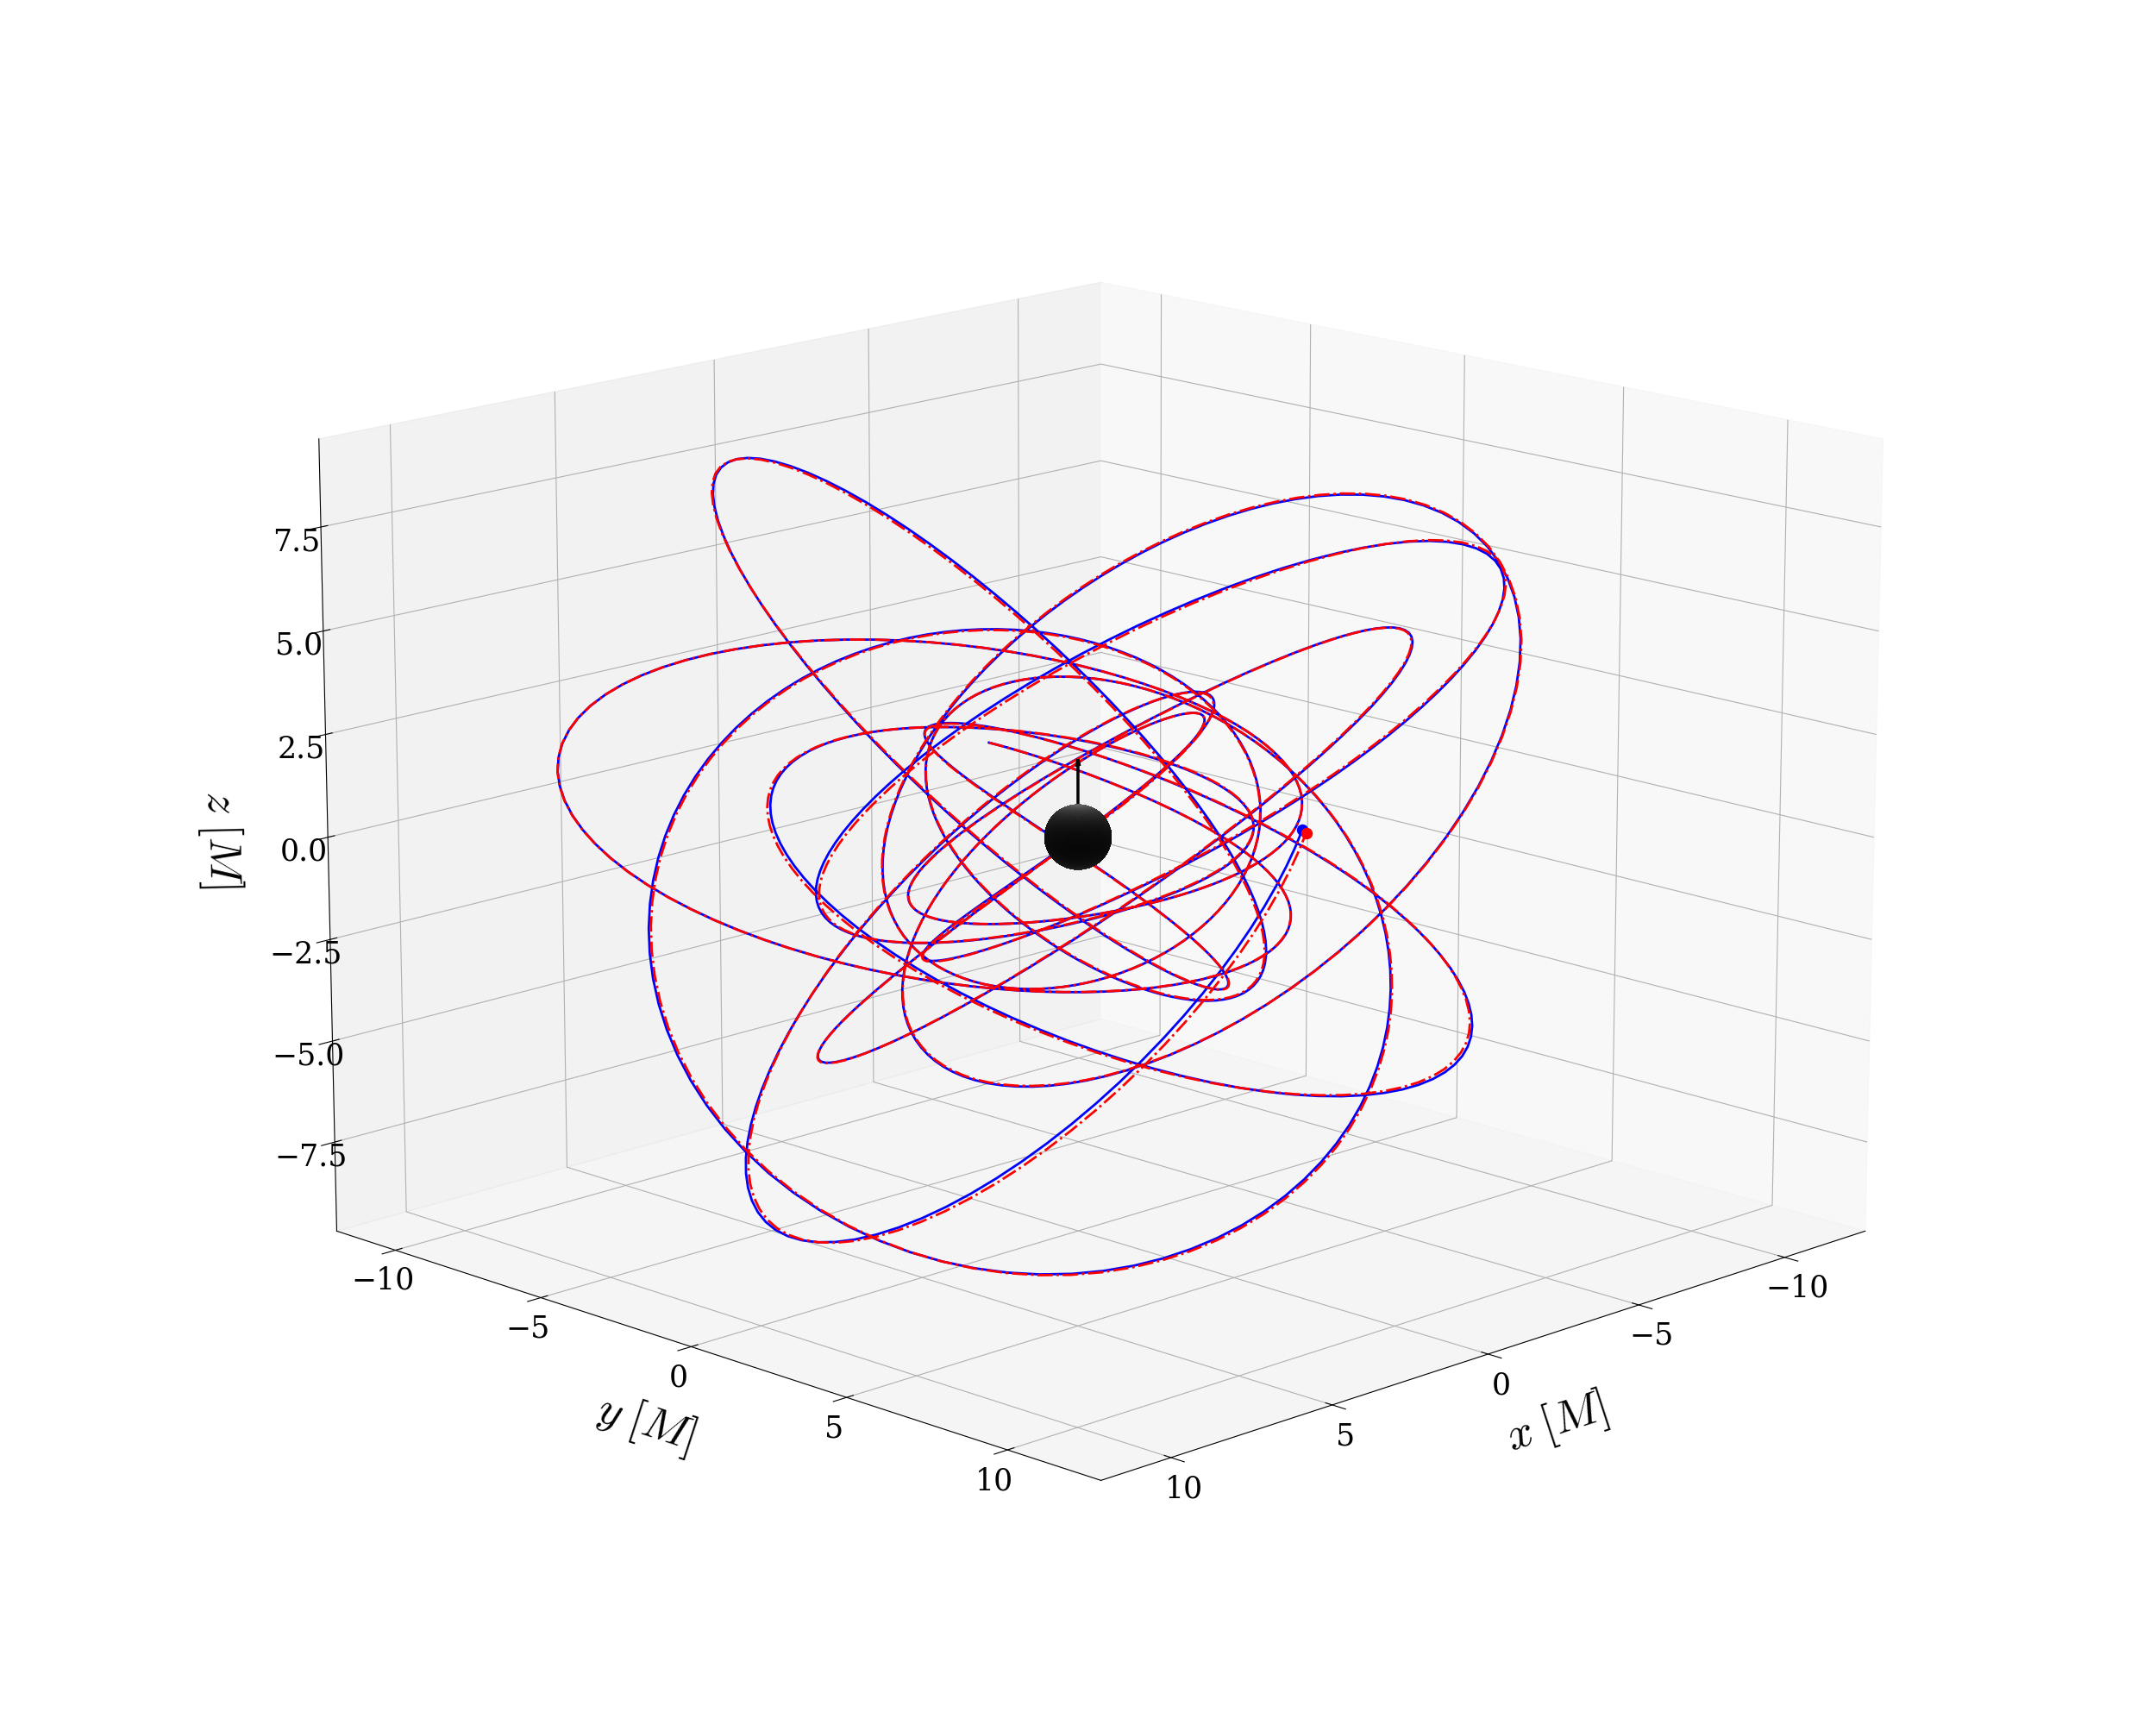

In [94]:
import kerrgeopy as kg
from matplotlib.colors import LightSource
from math import cos, pi
orbit = kg.StableOrbit(a, p0, e0, xI0)

x, y, z = spherical_to_cartesian(np.array(r(time)), 
                                np.array(theta(time)), 
                                np.array(phi(time)))

x_s, y_s, z_s = spherical_to_cartesian(r_spin, theta_spin, phi_spin)

# Plot trajectory
leng = 0
leng2 = -1

factor = 0.75
fig = plt.figure(figsize=(25,20))
plt.rc('xtick', labelsize=25)   # fontsize of the tick labels
plt.rc('ytick', labelsize=25)   # fontsize of the tick labels
ax = fig.add_subplot(111,projection = '3d')
ax.plot(x[leng:leng2],y[leng:leng2],z[leng:leng2], 'b-', lw=2)
ax.plot(x_s[leng:leng2],y_s[leng:leng2],z_s[leng:leng2], 'r-.', lw=2)

# Add black hole at origin (scale radius appropriately)
ax.quiver([0],[0],[0.65],[0],[0],[1.25], colors='black', linewidths=2.5, arrow_length_ratio=0.15)
bh_radius = 0.1 * max(r(time))  # Example scaling - adjust based on your M)
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 50)
x_p = np.outer(np.cos(u), np.sin(v))
y_p = np.outer(np.sin(u), np.sin(v))
z_p = np.outer(np.ones(np.size(u)), np.cos(v))
base_color = np.full(x_p.shape, 0.3)  # dark gray
ls = LightSource(azdeg=315, altdeg=45)
rgb = ls.shade_rgb(np.dstack([base_color]*3), z_p, vert_exag=1.0, blend_mode='soft')
ax.plot_surface(factor*x_p, factor*y_p, factor*z_p, facecolors=rgb, rstride=1, cstride=1, antialiased=False, alpha = 1)
ax.scatter(x[-2], y[-2],z[-2], color="blue", s=75)
ax.scatter(x_s[-2], y_s[-2],z_s[-2], color="r", s=75)
ax.set_xlabel('$x\;[M]$', fontsize=38, labelpad=30)
ax.set_ylabel('$y\;[M]$', fontsize=38, labelpad=30)
ax.set_zlabel('$z\;[M]$', fontsize=38, labelpad=30)
ax.view_init(elev=15, azim=45)
plt.tight_layout()
plt.savefig("Kerr_geodesics_spin_comparison.pdf")
plt.show()

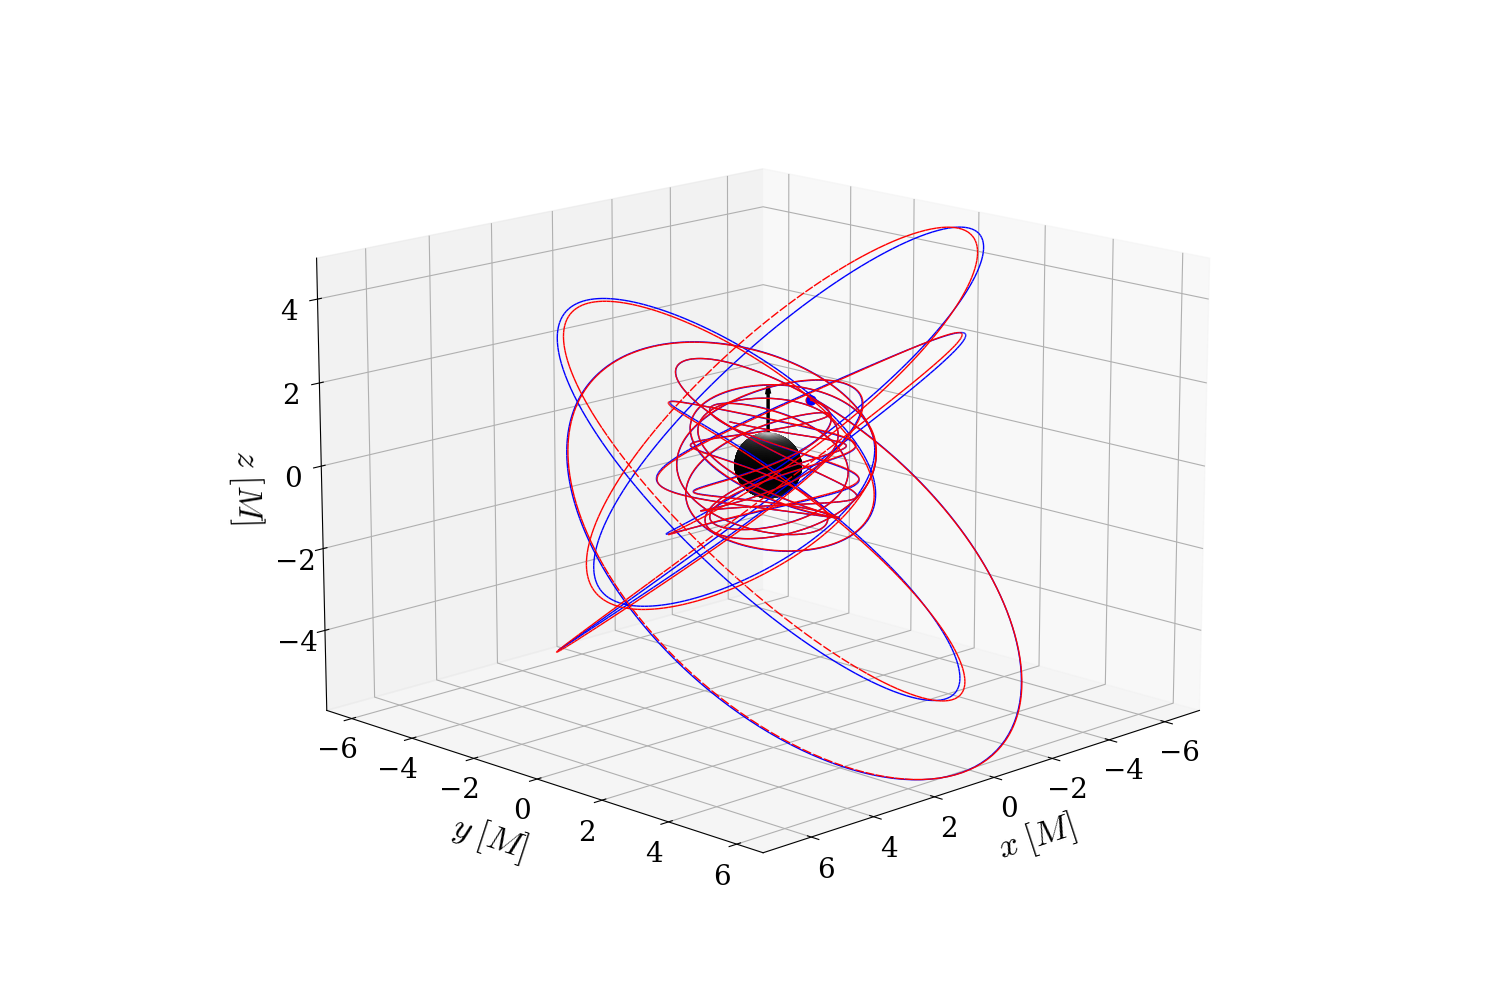

In [88]:
import kerrgeopy as kg
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource, to_rgba
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Line3DCollection

# Convert trajectories to Cartesian coordinates
x, y, z = spherical_to_cartesian(np.array(r(time)), 
                                 np.array(theta(time)), 
                                 np.array(phi(time)))
x_s, y_s, z_s = spherical_to_cartesian(r_spin, theta_spin, phi_spin)

# Create figure
factor = 0.75
bh_radius = factor  # Black hole radius
fig = plt.figure(figsize=(15, 10))
plt.rc('xtick', labelsize=20)
plt.rc('ytick', labelsize=20)
ax = fig.add_subplot(111, projection='3d')

# Set viewing angle
ax.view_init(elev=15, azim=45)

# Calculate camera direction vector
elev_rad = np.radians(15)
azim_rad = np.radians(45)
camera_direction = np.array([
    np.cos(azim_rad) * np.cos(elev_rad),
    np.sin(azim_rad) * np.cos(elev_rad),
    np.sin(elev_rad)
])

# Function to apply alpha based on occlusion
def apply_occlusion(ax, x, y, z, color, linestyle, bh_radius, camera_direction):
    points = np.column_stack([x, y, z])
    
    # Calculate projection and distance
    proj = np.dot(points, camera_direction)
    dist = np.linalg.norm(points, axis=1)
    
    # Create segments between points
    segments = []
    alphas = []
    base_rgba = to_rgba(color)
    
    for i in range(len(x) - 1):
        # Calculate midpoint for occlusion test
        midpoint = (points[i] + points[i+1]) / 2
        mid_dist = np.linalg.norm(midpoint)
        mid_proj = np.dot(midpoint, camera_direction)
        
        # Determine if segment is occluded
        occluded = (mid_proj < 0) and (mid_dist < bh_radius * 1.1)
        alpha = 0.3 if occluded else 1.0
        
        # Create segment with calculated alpha
        segments.append([[x[i], y[i], z[i]], [x[i+1], y[i+1], z[i+1]]])
        alphas.append(alpha)
    
    # Create RGBA colors for segments
    colors = [(base_rgba[0], base_rgba[1], base_rgba[2], a) for a in alphas]
    
    # Create Line3DCollection with specified linestyle
    lc = Line3DCollection(segments, colors=colors, linewidth=1, linestyle=linestyle)
    ax.add_collection(lc)
    return lc

# Plot trajectories with occlusion
non_spin_traj = apply_occlusion(ax, x, y, z, 'blue', '-', bh_radius, camera_direction)
# Spinning: dash-dot red line
spin_traj = apply_occlusion(ax, x_s, y_s, z_s, 'red', '-.', bh_radius, camera_direction)

# Create black hole surface
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 50)
x_p = bh_radius * np.outer(np.cos(u), np.sin(v))
y_p = bh_radius * np.outer(np.sin(u), np.sin(v))
z_p = bh_radius * np.outer(np.ones(np.size(u)), np.cos(v))
base_color = np.full(x_p.shape, 0.3)
ls = LightSource(azdeg=315, altdeg=45)
rgb = ls.shade_rgb(np.dstack([base_color]*3), z_p)
bh = ax.plot_surface(x_p, y_p, z_p, facecolors=rgb, 
                     rstride=1, cstride=1, alpha=1, zorder=3)

# Add arrow and endpoints
ax.quiver([0], [0], [0.65], [0], [0], [1.25], 
          colors='black', linewidths=2.5, arrow_length_ratio=0.15, zorder=4)
ax.scatter(x[-1], y[-1], z[-1], color="blue", s=40, zorder=4)
ax.scatter(x_s[-1], y_s[-1], z_s[-1], color="r", s=40, zorder=4)

# Set axis limits based on trajectories
all_x = np.concatenate([x, x_s])
all_y = np.concatenate([y, y_s])
all_z = np.concatenate([z, z_s])
ax.set_xlim([min(all_x), max(all_x)])
ax.set_ylim([min(all_y), max(all_y)])
ax.set_zlim([min(all_z), max(all_z)])

# Axis labels
ax.set_xlabel('$x\;[M]$', fontsize=25, labelpad=15)
ax.set_ylabel('$y\;[M]$', fontsize=25, labelpad=15)
ax.set_zlabel('$z\;[M]$', fontsize=25, labelpad=10)

plt.tight_layout()
plt.savefig("Kerr_geodesics_spin_comparison.pdf")
plt.show()

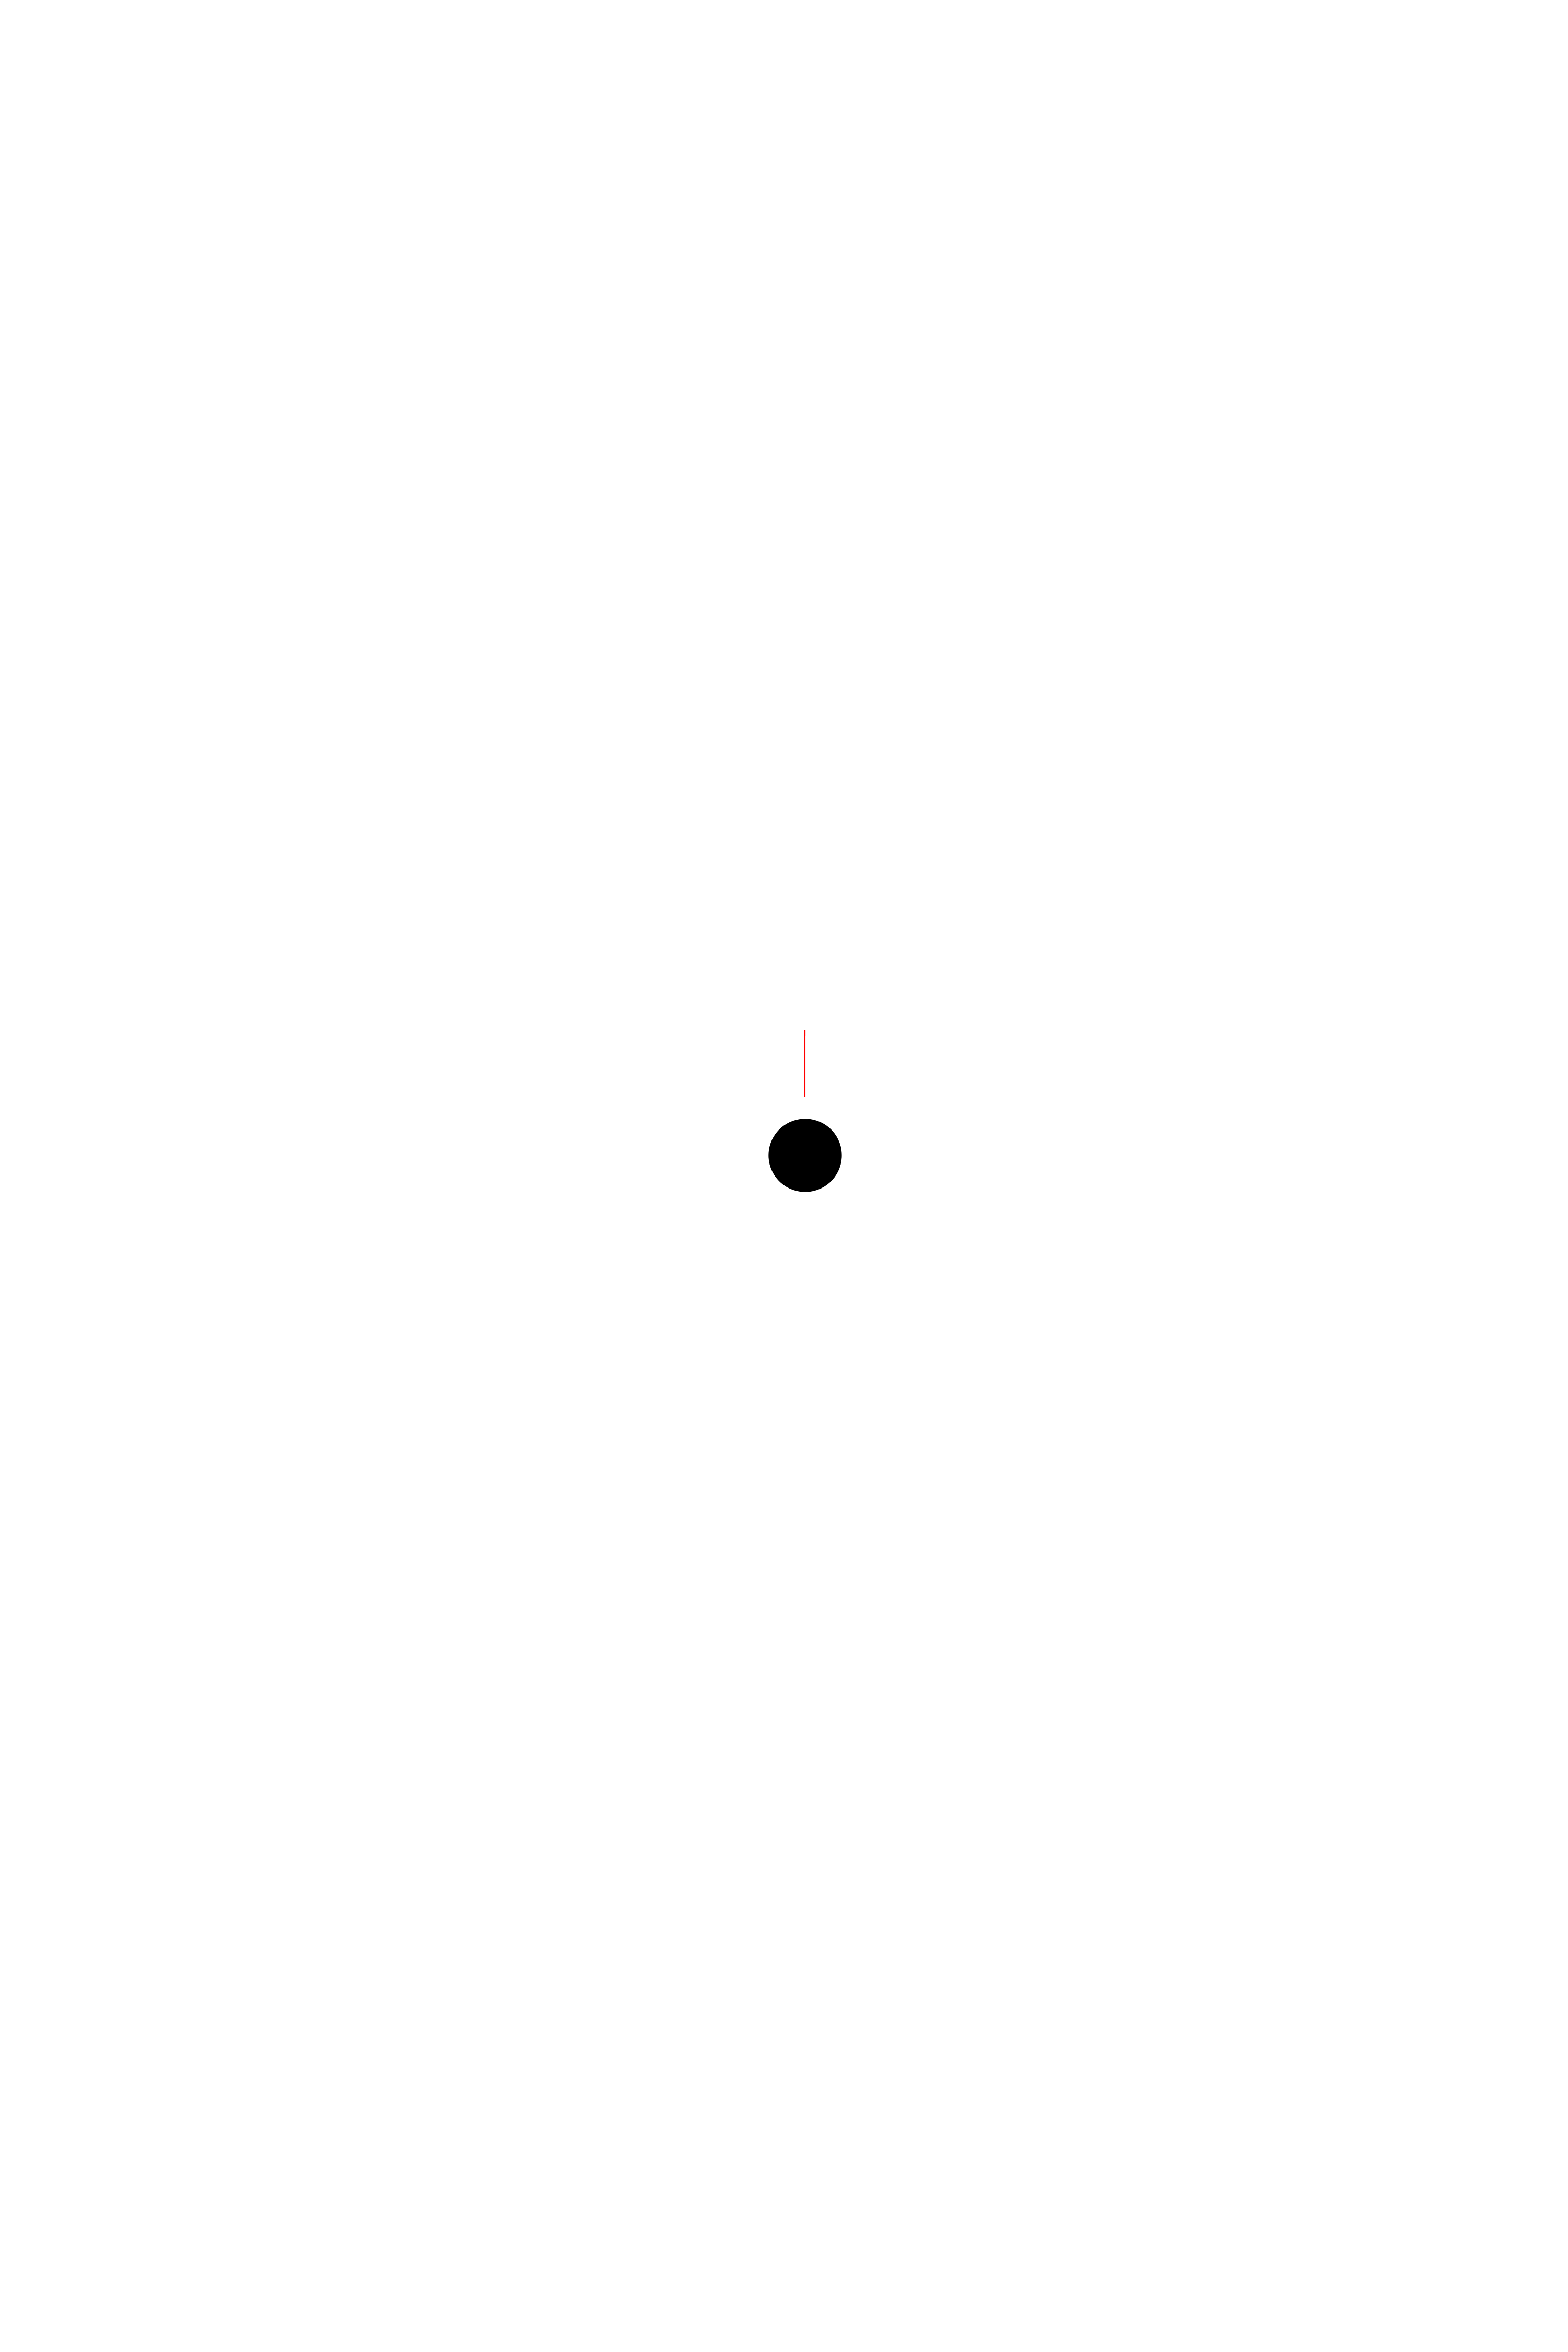

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7f651b7c6670>>
Traceback (most recent call last):
  File "/home/llui/anaconda3/envs/emri_env/lib/python3.9/site-packages/ipykernel/ipkernel.py", line 770, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 
Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x7f651b7c6670>>
Traceback (most recent call last):
  File "/home/llui/anaconda3/envs/emri_env/lib/python3.9/site-packages/ipykernel/ipkernel.py", line 770, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 

KeyboardInterrupt



In [90]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LightSource
import kerrgeopy as kg

# Create figure and axis
fig = plt.figure(figsize=(30, 45))
ax = fig.add_subplot(111, projection='3d')

# Plot static elements
factor = 1

# Black hole sphere
#u = np.linspace(0, 2 * np.pi, 400)
#v = np.linspace(0, np.pi, 200)
#x_p = np.outer(np.cos(u), np.sin(v))
#y_p = np.outer(np.sin(u), np.sin(v))
#z_p = np.outer(np.ones(np.size(u)), np.cos(v))
#base_color = np.full(x_p.shape, 0.0)
#ls = LightSource(azdeg=315, altdeg=45)
#rgb = ls.shade_rgb(np.dstack([base_color]*3), z_p, vert_exag=1.0, blend_mode='soft')
#bh_sphere = ax.plot_surface(factor*x_p, factor*y_p, factor*z_p, facecolors=rgb, 
                           #rstride=1, cstride=1, antialiased=False, alpha=1)

# Spin indicator at origin
spin_indicator = ax.quiver([0], [0], [1.3], [0], [0], [1.5], color='r', linewidths=1.5, arrow_length_ratio=0.1)
bh_sphere =ax.plot(0, 0, 0, 'ko', markersize=100)

# Initialize dynamic elements
non_spinning_trail, = ax.plot([], [], [], 'b-', lw=1, alpha=1.0)
spinning_trail, = ax.plot([], [], [], 'r-', lw=1, alpha=1.0)
current_sphere_point, = ax.plot([], [], [], 'bo', markersize=3)
current_sphere_point_spin, = ax.plot([], [], [], 'ro', markersize=3)
current_quiver = None  # Will store the current quiver

# Configure plot aesthetics
ax.grid(False)
ax.set_axis_off()
ax.set_facecolor('white')
initial_elev = 10
ax.view_init(elev=initial_elev, azim=0)

# Set axis limits
max_range = max(np.max(np.abs(x)), np.max(np.abs(y)), np.max(np.abs(z)),
               np.max(np.abs(x_s)), np.max(np.abs(y_s)), np.max(np.abs(z_s))) * 1.1
ax.set_xlim(-max_range, max_range)
ax.set_ylim(-max_range, max_range)
ax.set_zlim(-max_range, max_range)

# Parameters for laser trail effect
TRAIL_LENGTH = 25
ALPHA_DECAY = 0.98

# Create a subset of frames to reduce rendering load
total_frames = len(time)
frame_step = 5  # Use every 10th frame (reduces total frames to 150)
frame_indices = np.arange(0, total_frames, frame_step) 

# Precompute rotation angles for smoother rotation
rotation_angles = 720 * (frame_indices / (total_frames - 1))

# Animation update function
def update(i):
    global current_quiver
    
    frame = frame_indices[i]
    
    # Set rotation
    ax.view_init(elev=initial_elev, azim=rotation_angles[i])

    # Calculate start index for trails
    start_idx = max(0, frame - TRAIL_LENGTH)
    
    # Update trails
    non_spinning_trail.set_data(x[start_idx:frame+1], y[start_idx:frame+1])
    non_spinning_trail.set_3d_properties(z[start_idx:frame+1])
    spinning_trail.set_data(x_s[start_idx:frame+1], y_s[start_idx:frame+1])
    spinning_trail.set_3d_properties(z_s[start_idx:frame+1])
    
    # Apply fading alpha
    trail_alpha = ALPHA_DECAY ** (frame - start_idx)
    non_spinning_trail.set_alpha(trail_alpha)
    spinning_trail.set_alpha(trail_alpha)
    
    # Update particle positions
    current_sphere_point.set_data([x[frame]], [y[frame]])
    current_sphere_point.set_3d_properties([z[frame]])
    current_sphere_point_spin.set_data([x_s[frame]], [y_s[frame]])
    current_sphere_point_spin.set_3d_properties([z_s[frame]])
    
    # Update quiver for spin vector
    if current_quiver is not None:
        current_quiver.remove()
        
    # Create new quiver at spinning particle position
    current_quiver = ax.quiver(
        [x_s[frame]], [y_s[frame]], [z_s[frame]],
        [Sx[frame]], [Sy[frame]], [Sz[frame]],
        color='red', arrow_length_ratio=0.25, alpha=1, linewidths=1.5
    )
    
    return [non_spinning_trail, spinning_trail, 
            current_sphere_point, current_sphere_point_spin,
            current_quiver]

# Create animation with slower settings
# Key parameters for controlling speed:
#   interval: Time between frames in milliseconds (higher = slower)
#   fps: Frames per second in saved animation (lower = slower)
interval_val = 800  # 400 ms between frames (0.4 seconds)
ani = FuncAnimation(
    fig, update, frames=len(frame_indices), 
    interval=interval_val, blit=False, repeat=False
)

plt.tight_layout()
plt.show()

# Save the animation with slower playback
# 5 FPS = 5 frames per second = 0.2 seconds per frame
ani.save('kerr_orbits_animation_trail_white.gif', writer='pillow', fps=10, dpi=100)

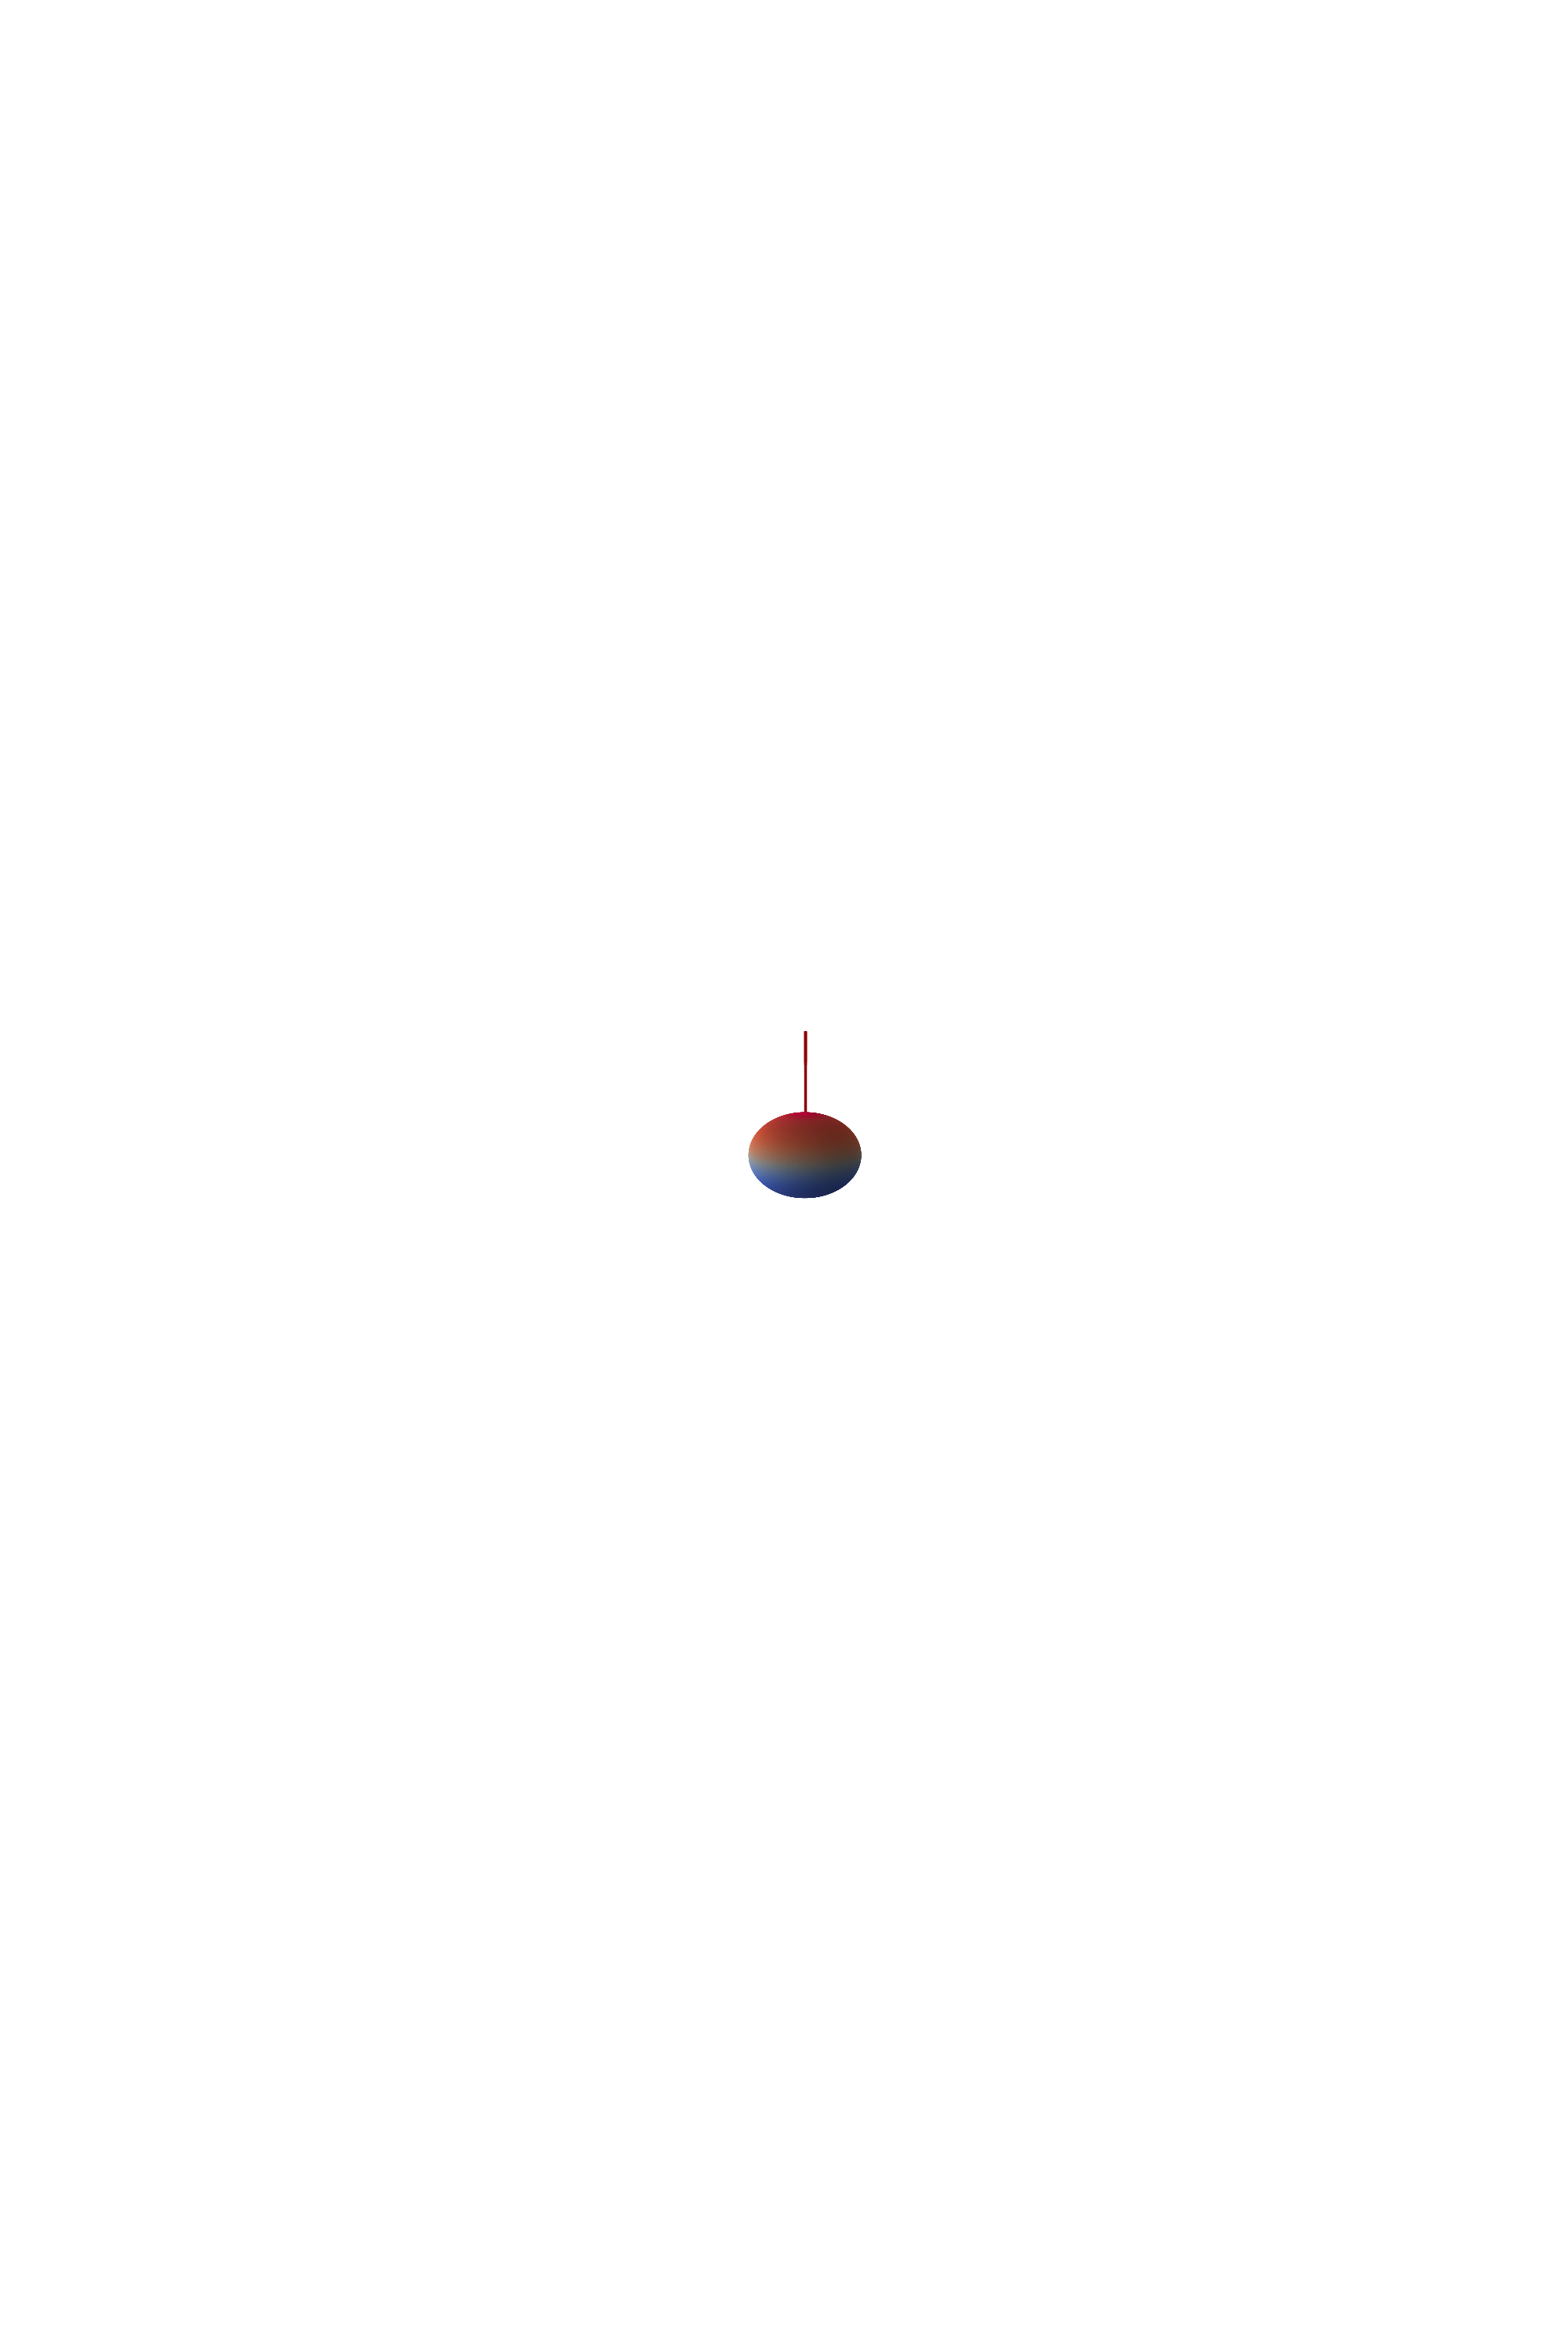

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from matplotlib.colors import LightSource
import kerrgeopy as kg

# Create figure with white background
fig = plt.figure(figsize=(20, 30), facecolor='white')
ax = fig.add_subplot(111, projection='3d')

# Higher resolution for black hole sphere
u = np.linspace(0, 2 * np.pi, 200)  # Increased from 100
v = np.linspace(0, np.pi, 100)      # Increased from 50
x_p = np.outer(np.cos(u), np.sin(v))
y_p = np.outer(np.sin(u), np.sin(v))
z_p = np.outer(np.ones(np.size(u)), np.cos(v))

# Create smoother shading for black hole
base_color = np.full(x_p.shape, 0.0)  # Darker base color
ls = LightSource(azdeg=315, altdeg=45)
# Use coolwarm colormap for more realistic shading
shaded_rgb = ls.shade(z_p, cmap=plt.cm.coolwarm, vert_exag=1.0, blend_mode='soft')

# Plot black hole with higher resolution
factor = 1
bh_sphere = ax.plot_surface(factor*x_p, factor*y_p, factor*z_p, 
                           facecolors=shaded_rgb, 
                           rstride=2, cstride=2,  # Reduced stride for smoother surface
                           antialiased=True, alpha=1)

# Spin indicator at origin - make it more visible on white background
spin_indicator = ax.quiver([0], [0], [1], [0], [0], [2], 
                          color='darkred', linewidths=2.5, arrow_length_ratio=0.4)

# Initialize dynamic elements
non_spinning_trail, = ax.plot([], [], [], 'b-', lw=1.5, alpha=1.0)
spinning_trail, = ax.plot([], [], [], 'r-', lw=1.5, alpha=1.0)
current_sphere_point, = ax.plot([], [], [], 'bo', markersize=4)
current_sphere_point_spin, = ax.plot([], [], [], 'ro', markersize=4)
current_quiver = None

# Configure plot aesthetics - white background
ax.grid(False)
ax.set_axis_off()
ax.set_facecolor('white')  # White background

# Set view and axis limits
initial_elev = 10
ax.view_init(elev=initial_elev, azim=0)
max_range = max(np.max(np.abs(x)), np.max(np.abs(y)), np.max(np.abs(z)),
               np.max(np.abs(x_s)), np.max(np.abs(y_s)), np.max(np.abs(z_s))) * 1.1
ax.set_xlim(-max_range, max_range)
ax.set_ylim(-max_range, max_range)
ax.set_zlim(-max_range, max_range)

# Parameters for laser trail effect
TRAIL_LENGTH = 50  # Longer trail for smoother appearance
ALPHA_DECAY = 0.98  # Slower fade

# Create a subset of frames for smoother animation
total_frames = len(time)
frame_step = 2  # More frames for smoother motion
frame_indices = np.arange(0, total_frames, frame_step) 
rotation_angles = 720 * (frame_indices / (total_frames - 1))

# Animation update function
def update(i):
    global current_quiver
    
    frame = frame_indices[i]
    
    # Set rotation
    ax.view_init(elev=initial_elev, azim=rotation_angles[i])

    # Calculate start index for trails
    start_idx = max(0, frame - TRAIL_LENGTH)
    
    # Update trails
    non_spinning_trail.set_data(x[start_idx:frame+1], y[start_idx:frame+1])
    non_spinning_trail.set_3d_properties(z[start_idx:frame+1])
    spinning_trail.set_data(x_s[start_idx:frame+1], y_s[start_idx:frame+1])
    spinning_trail.set_3d_properties(z_s[start_idx:frame+1])
    
    # Apply fading alpha
    trail_alpha = ALPHA_DECAY ** (frame - start_idx)
    non_spinning_trail.set_alpha(trail_alpha)
    spinning_trail.set_alpha(trail_alpha)
    
    # Update particle positions
    current_sphere_point.set_data([x[frame]], [y[frame]])
    current_sphere_point.set_3d_properties([z[frame]])
    current_sphere_point_spin.set_data([x_s[frame]], [y_s[frame]])
    current_sphere_point_spin.set_3d_properties([z_s[frame]])
    
    # Update quiver for spin vector
    if current_quiver is not None:
        current_quiver.remove()
        
    # Create new quiver at spinning particle position
    current_quiver = ax.quiver(
        [x_s[frame]], [y_s[frame]], [z_s[frame]],
        [Sx[frame]], [Sy[frame]], [Sz[frame]],
        color='darkred', arrow_length_ratio=0.3, alpha=1, linewidths=2.0
    )
    
    return [non_spinning_trail, spinning_trail, 
            current_sphere_point, current_sphere_point_spin,
            current_quiver]

# Create animation with smoother settings
ani = FuncAnimation(
    fig, update, frames=len(frame_indices), 
    interval=50,  # Faster updates for smoother motion
    blit=False, repeat=False
)

plt.tight_layout()
plt.show()

# Save as MP4 with high quality
writer = FFMpegWriter(fps=30, metadata=dict(artist='Me'), bitrate=5000)
ani.save('kerr_orbits_animation.mp4', writer=writer, dpi=150)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LightSource
import kerrgeopy as kg
x, y, z = spherical_to_cartesian(np.array(r(time)), 
                                np.array(theta(time)), 
                                np.array(phi(time)))

x_s, y_s, z_s = spherical_to_cartesian(r_spin, theta_spin, phi_spin)
# Create figure and axis
fig = plt.figure(figsize=(10, 15))
ax = fig.add_subplot(111, projection='3d')

# Plot static elements
factor = 0.8

# Black hole sphere
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 50)
x_p = np.outer(np.cos(u), np.sin(v))
y_p = np.outer(np.sin(u), np.sin(v))
z_p = np.outer(np.ones(np.size(u)), np.cos(v))
base_color = np.full(x_p.shape, 0.3)
ls = LightSource(azdeg=315, altdeg=45)
rgb = ls.shade_rgb(np.dstack([base_color]*3), z_p, vert_exag=1.0, blend_mode='soft')
bh_sphere = ax.plot_surface(factor*x_p, factor*y_p, factor*z_p, facecolors=rgb, 
                           rstride=1, cstride=1, antialiased=False, alpha=1)

# Spin indicator at origin
spin_indicator = ax.quiver([0], [0], [0.75], [0], [0], [2], color='r', linewidths=1.5, arrow_length_ratio=0.25)

# Static trajectories (both drawn fully at start)
non_spinning_traj, = ax.plot([], [], [], 'b-', lw=1, alpha=1.0)
spinning_traj, = ax.plot([], [], [], 'r-.', lw=1, alpha=1.0)

# Initialize dynamic elements
# Use comma to get single artist instead of list
current_sphere_point, = ax.plot([], [], [], 'bo', markersize=3)
current_sphere_point_spin, = ax.plot([], [], [], 'ro', markersize=3)
quivers = []  # For storing spin vectors
quiver_holder = [None]  # Current quiver object

# Configure plot aesthetics
ax.grid(False)
ax.set_axis_off()
ax.set_facecolor('black')
initial_elev = 10
ax.view_init(elev=initial_elev, azim=0)

# Set axis limits
max_range = max(np.max(np.abs(x)), np.max(np.abs(y)), np.max(np.abs(z)),
               np.max(np.abs(x_s)), np.max(np.abs(y_s)), np.max(np.abs(z_s))) * 1.1
ax.set_xlim(-max_range, max_range)
ax.set_ylim(-max_range, max_range)
ax.set_zlim(-max_range, max_range)

# Animation update function
def update(frame):
    # Rotate view (4π radians = 720 degrees over the animation)
    rotation_angle = 720 * (frame / (len(time) - 1)) if len(time) > 1 else 0
    ax.view_init(elev=initial_elev, azim=rotation_angle)

    #update trajectories
    non_spinning_traj.set_data(x[:frame], y[:frame])
    non_spinning_traj.set_3d_properties(z[:frame])
    spinning_traj.set_data(x_s[:frame], y_s[:frame])
    spinning_traj.set_3d_properties(z_s[:frame])
    
    # Update non-spinning particle position
    current_sphere_point.set_data([x[frame]], [y[frame]])
    current_sphere_point.set_3d_properties([z[frame]])
    
    # Update spinning particle position
    current_sphere_point_spin.set_data([x_s[frame]], [y_s[frame]])
    current_sphere_point_spin.set_3d_properties([z_s[frame]])
    
    # Update quiver for spin vector
    if quiver_holder[0] is not None:
        quiver_holder[0].remove()
    
    # Create new quiver at spinning particle position
    new_quiver = ax.quiver(
        [x_s[frame]], [y_s[frame]], [z_s[frame]],
        [Sx[frame]], [Sy[frame]], [Sz[frame]],
        color='red', arrow_length_ratio=0.25, alpha=1, linewidths=1.5
    )
    quiver_holder[0] = new_quiver
    quivers.append(new_quiver)  # Store reference to prevent garbage collection
    
    # Return artists that need updating
    return [non_spinning_traj, spinning_traj, 
            current_sphere_point, current_sphere_point_spin,
            new_quiver] + quivers

# Create animation
step = 2  # Reduce for smoother animation but longer render time
ani = FuncAnimation(
    fig, update, frames=range(0, len(time), step), 
    interval=100, blit=False, repeat=False
)

plt.tight_layout()
plt.show()

# Save the animation
ani.save('kerr_orbits_animation.gif', writer='pillow', fps=30, dpi=100)

In [ ]:
time = np.linspace(0,10,500)
acc = spin_curvature_acc(time[2], q, a, p0, e0, xI0, 0.5, np.pi/4, np.pi/4, qr0=qr0, qz0=qz0)

In [2]:
E_dot, L_dot, K_dot = ELK_spin_evolution(time[1], q, a, p0, e0, xI0, 0.5, np.pi/4, np.pi/4,  qr0=qr0, qz0=qz0)

NameError: name 'ELK_spin_evolution' is not defined

In [8]:
E_dot, L_dot, K_dot

(0.007526744325109819, 0.09536208292969357, -0.18802016321112328)

In [9]:
p_array = [p0]
e_array = [e0]
qr_array = []
chi_r_array = [chi_r]
for i in range(1,len(time)):
    dt = time[i]-time[i-1]
    q_to_chi()
    pd, ed, xd = pex_spin_evolution(time[i], q, a, p_array[-1], e_array[-1], xI0, 0.5, np.pi/4, np.pi/4, qr_array[-1], chi_phi)
    q_rd, q_theta_d = phase_spin_evolution(time[i], q, a, p_array[-1], e_array[-1], xI0, 0.5, np.pi/4, np.pi/4, qr_array[-1], chi_phi)
    p_array.append(p_array[-1]+pd*dt)
    e_array.append(e_array[-1]+ed*dt)
    qr_array.append(qr_array[-1]+q_rd*dt)
    
p_array = np.array(p_array)
e_array = np.array(e_array)
qr_array = np.array(qr_array)

NameError: name 'chi_r' is not defined

NameError: name 'chi_r_array' is not defined

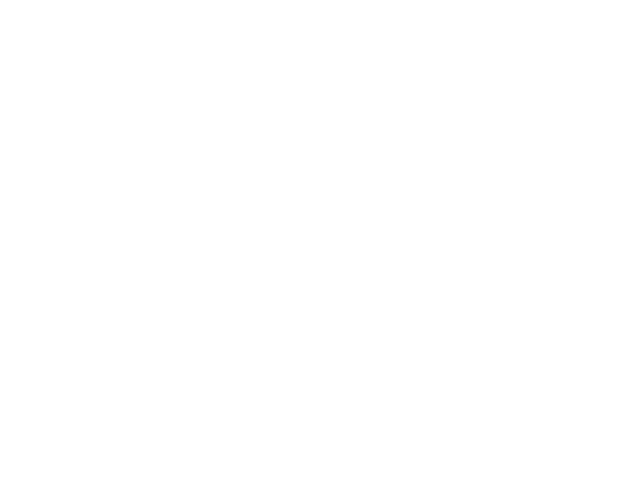

In [16]:
plt.figure()
plt.plot(p_array/(1+e_array*np.cos(chi_r_array)))
plt.plot(r(time))

In [17]:
from scipy import linalg
spacetime = kg.KerrSpacetime(a=a, M=1)
Kerr_cov = spacetime.metric(0, r, theta, 0)
Kerr_contra = spacetime.metric_inv(0, r, theta, 0)
spacetime.norm(a, r, theta, 0, np.dot(e0_vec,Kerr_contra))

TypeError: unsupported operand type(s) for ** or pow(): 'function' and 'int'

In [55]:
np.max(Sx), np.max(Sy), np.max(Sz)

(0.006032735817683996, 0.00022242253362802006, 0.1004221646372973)

In [51]:
S_vec

[array([ 0.01213938,  0.01105875, -0.02660581, -0.09739704]),
 array([ 0.01230262,  0.01058462, -0.02734558, -0.09794422]),
 array([ 0.01249589,  0.01000352, -0.0282094 , -0.09858583]),
 array([ 0.01271263,  0.0093243 , -0.02916119, -0.09929655]),
 array([ 0.01294688,  0.00855405, -0.03016777, -0.10005322]),
 array([ 0.01319318,  0.00769872, -0.0311982 , -0.10083431]),
 array([ 0.01344641,  0.00676354, -0.03222344, -0.10161962]),
 array([ 0.01370173,  0.0057534 , -0.03321594, -0.10239002]),
 array([ 0.01395451,  0.00467311, -0.03414944, -0.10312726]),
 array([ 0.01420032,  0.00352754, -0.03499887, -0.10381388]),
 array([ 0.01443485,  0.00232183, -0.03574024, -0.10443311]),
 array([ 0.01465394,  0.00106143, -0.03635063, -0.10496892]),
 array([ 0.01485358, -0.00024777, -0.0368083 , -0.10540599]),
 array([ 0.01502989, -0.00159941, -0.03709271, -0.1057298 ]),
 array([ 0.01517917, -0.00298662, -0.0371847 , -0.1059267 ]),
 array([ 0.0152979 , -0.00440204, -0.03706659, -0.10598399]),
 array([

In [8]:
e0_vec, e1_vec, e2_vec, e3_vec = [], [], [], []
S_vec = []
q = 1e-5
qpsi = 0.0
for i in range(len(time)):
    e0_vec.append(Marck_tetrad(time[i], a, p0, e0, xI0, qr0=qr0, qz0=qz0, qpsi0 = qpsi)[0])
    e1_vec.append(Marck_tetrad(time[i], a, p0, e0, xI0, qr0=qr0, qz0=qz0, qpsi0 = qpsi)[1])
    e2_vec.append(Marck_tetrad(time[i], a, p0, e0, xI0, qr0=qr0, qz0=qz0, qpsi0 = qpsi)[2])
    e3_vec.append(Marck_tetrad(time[i], a, p0, e0, xI0, qr0=qr0, qz0=qz0, qpsi0 = qpsi)[3])
    #qpsi.append(psi_phase(time[i], a, p0, e0, xI0, qr0=qr0, qz0=qz0, qpsi0 = qpsi[-1]))
    S_vec.append(spin_vector(time[i], q, a, p0, e0, xI0, 0.04, np.pi/4, np.pi/4,  qr0=qr0, qz0=qz0, qpsi0 = qpsi))

In [36]:
import kerrgeopy as kg
from math import cos, pi

orbit = kg.StableOrbit(a, p0, e0, xI0, initial_phases=(0, qr0, qz0, 0))

t, r, theta, phi = orbit.trajectory()

In [37]:
x, y, z = spherical_to_cartesian(np.array(r(time)), 
                                np.array(theta(time)), 
                                np.array(phi(time)))

In [38]:
r, _, _ = radial_solutions(a, constants, radial_roots)

In [39]:
Upsilon_r, Upsilon_theta, Upsilon_phi, Gamma = mino_frequencies(a, p0, e0, xI0)

In [16]:
np.max(Sx), np.max(Sy), np.mean(Sz)

(0.1348579199567241, 0.007961551941033413, 0.0015133757582474602)

In [10]:
np.max(Sx), np.max(Sy), np.mean(Sz)

(0.05779625141002462, 0.00341209368901432, 0.0006485896106774802)

In [9]:
len(time)

150

In [11]:
Sx, Sy, Sz = [], [], []
lamb = np.linspace(0,len(time)-1,len(time)+1)
for i in lamb:
    widths = 1
    j = int(i)
    Sx_j, Sy_j, Sz_j = spherical_to_cartesian(S_vec[j][1], S_vec[j][2], S_vec[j][3])
    Sx.append(15*Sx_j)
    Sy.append(15*Sy_j)
    Sz.append(15*Sz_j)

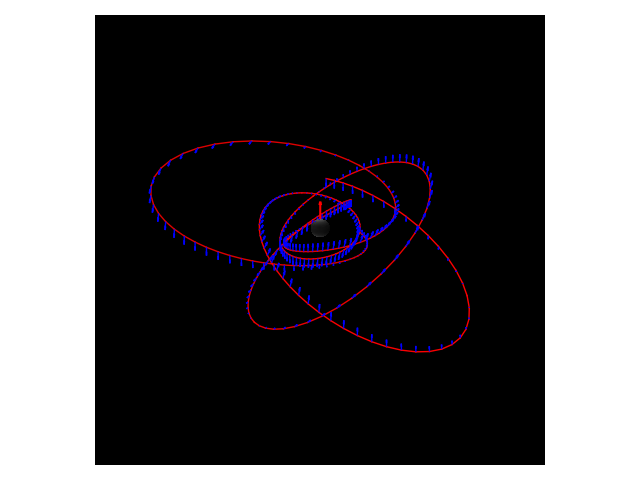

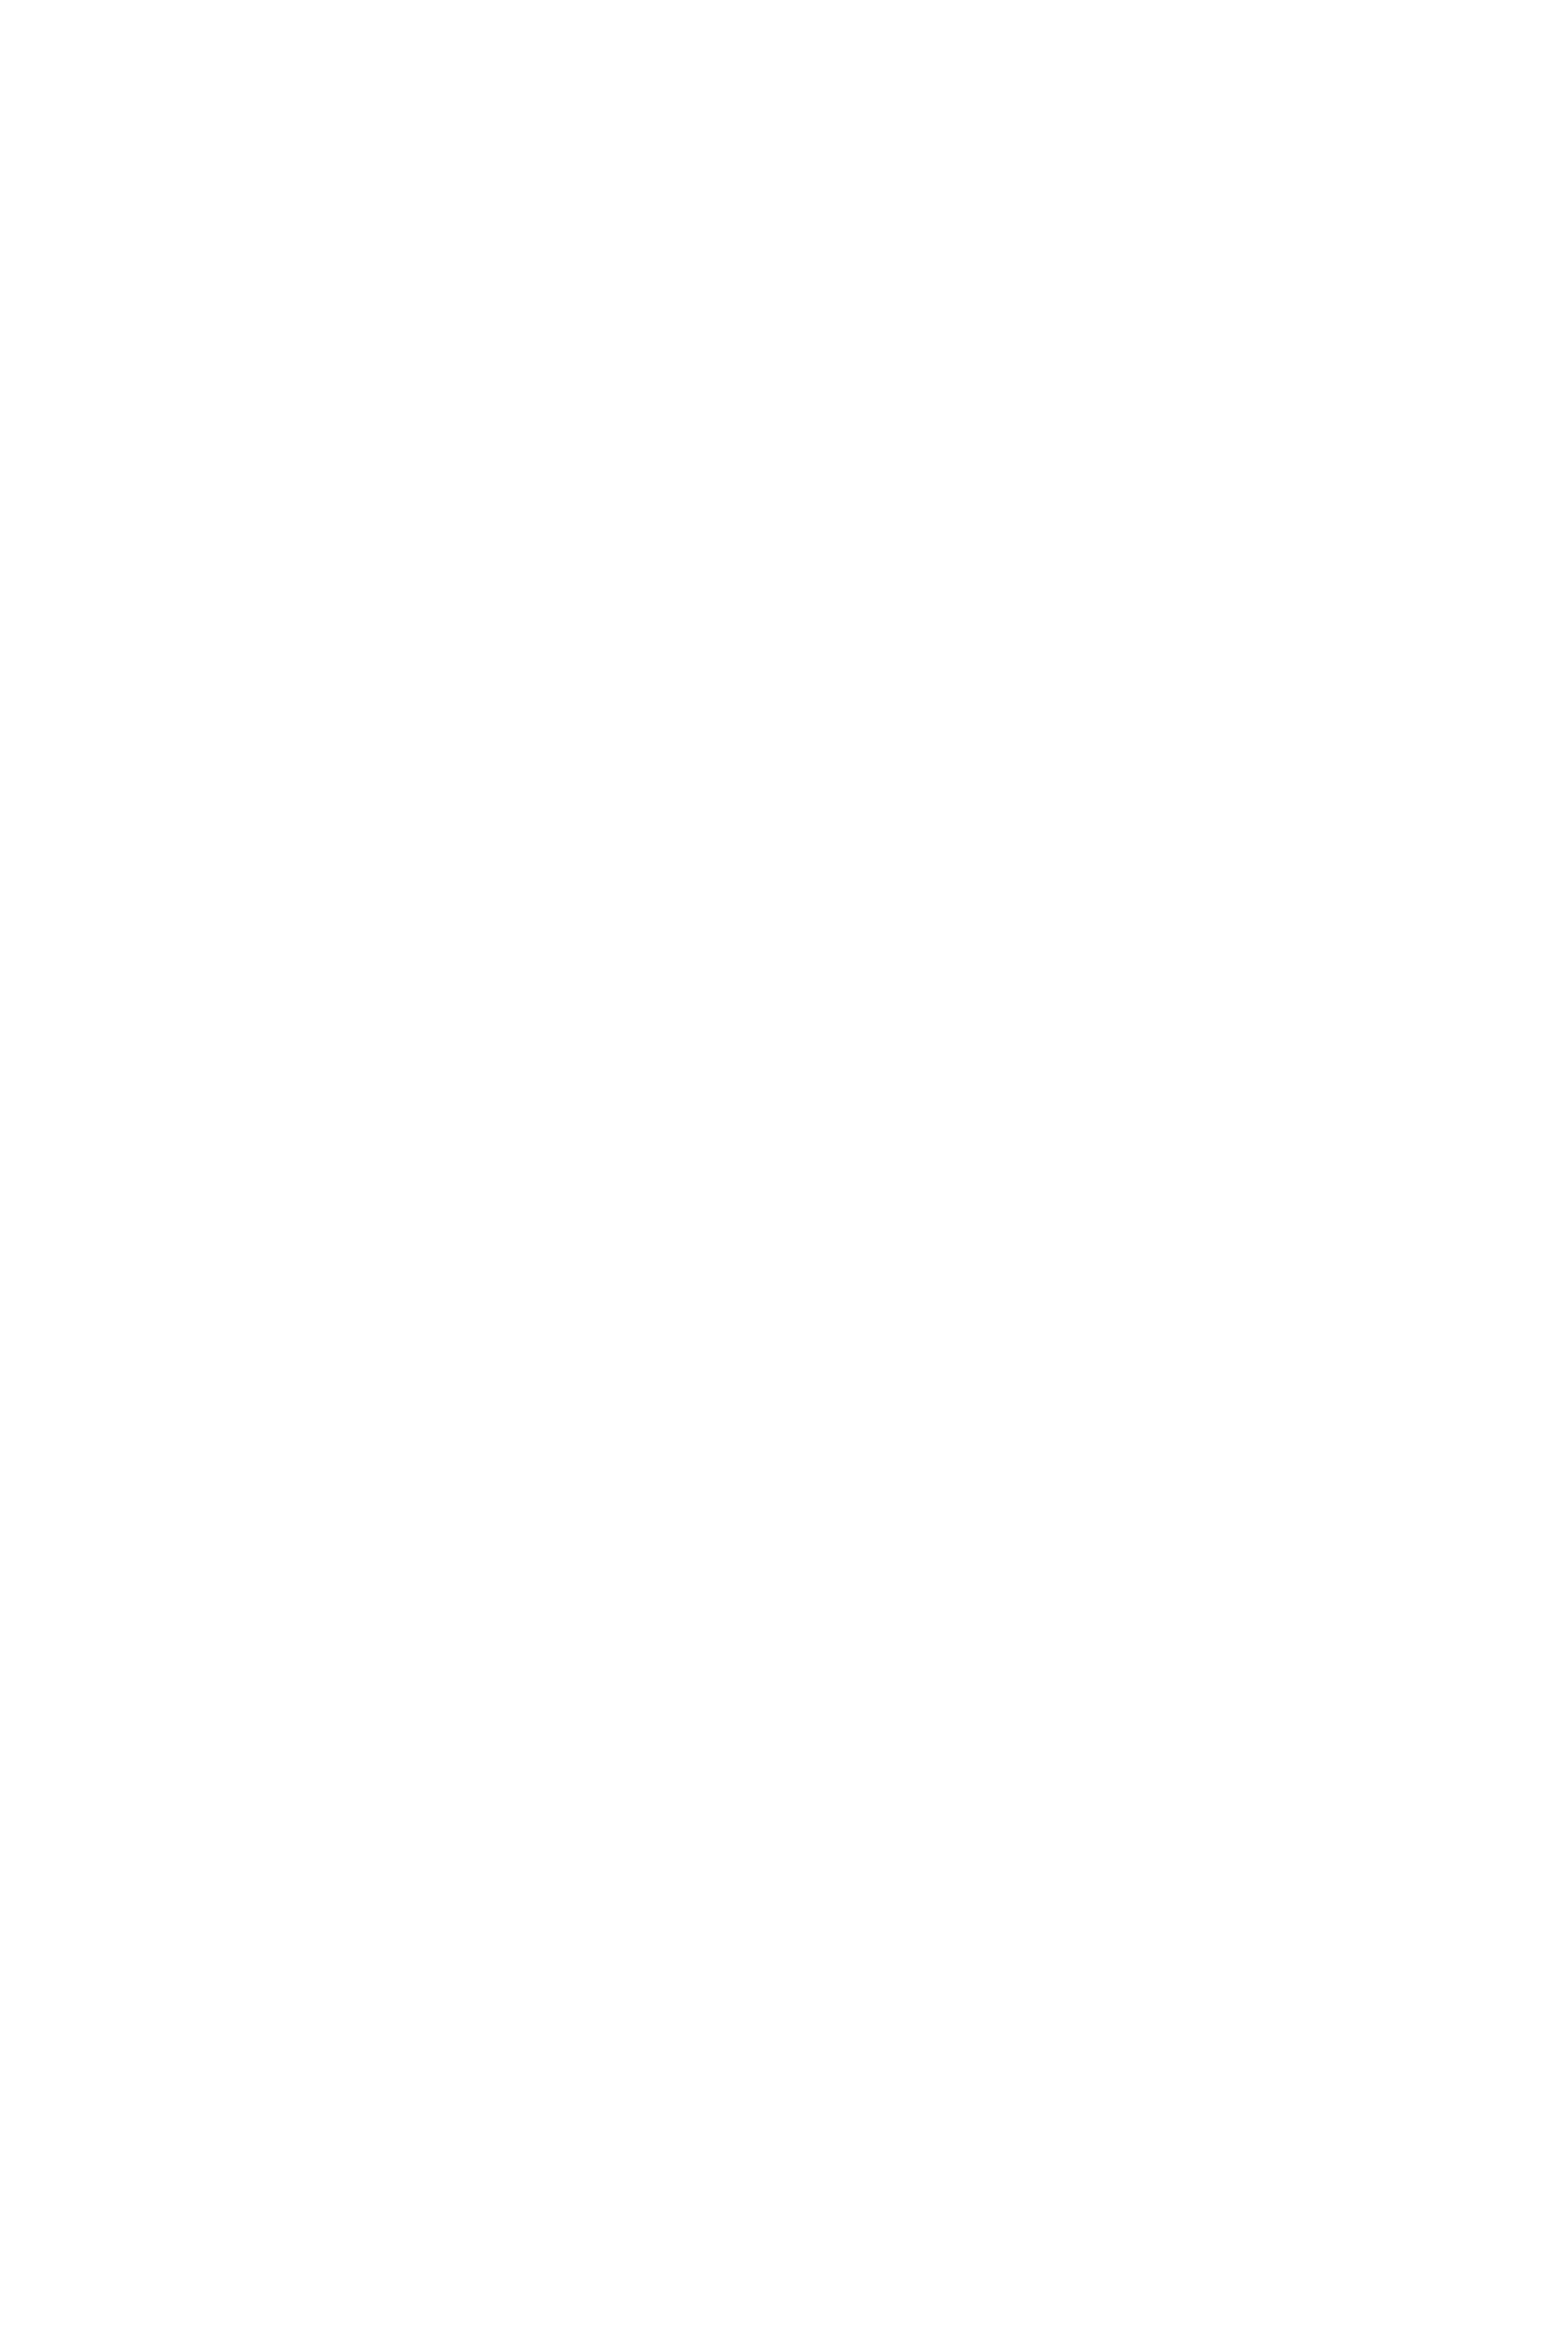

In [74]:
plt.figure(figsize=(30, 45))
from matplotlib.colors import LightSource
from matplotlib import cm
# Plot trajectory
fig, ax = plot_fading_line_3d(x, y, z, time, tau=30, color='r', lw=1)


# Add black hole at origin (scale radius appropriately)
ax.quiver([0],[0],[0.75],[0],[0],[1.5], colors='r', linewidths=1.5, arrow_length_ratio=0.2)
bh_radius = 0.1 * max(r(time))  # Example scaling - adjust based on your M)
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 50)
x_p = np.outer(np.cos(u), np.sin(v))
y_p = np.outer(np.sin(u), np.sin(v))
z_p = np.outer(np.ones(np.size(u)), np.cos(v))
base_color = np.full(x_p.shape, 0.3)  # dark gray
ls = LightSource(azdeg=315, altdeg=45)
rgb = ls.shade_rgb(np.dstack([base_color]*3), z_p, vert_exag=1.0, blend_mode='soft')
ax.plot_surface(0.65*x_p, 0.65*y_p, 0.65*z_p, facecolors=rgb, rstride=1, cstride=1, antialiased=False, alpha = 1)
# Add coordinate system

#ax.scatter([0], [0], [0], c='black', s=500*bh_radius, label='Black Hole')


#ax.scatter(x[-1], y[-1], z[-1], c='black', s=30*bh_radius, label='Black Hole')
lamb = np.linspace(0,299,301)

for i in lamb:
    widths = 1
    j = int(i)
    #ax.quiver([x[j]],[y[j]],[z[j]],[e1_vec[j]*np.sin(theta(time)[j])*np.cos(phi(time)[j])],[e1_vec[j]*np.sin(theta(time)[j])*np.sin(phi(time)[j])],
              #[e1_vec[j]*np.cos(theta(time)[j])], colors='r', linewidths=widths)
    #ax.quiver([x[j]],[y[j]],[z[j]],[0],[e2_vec[j]],[0], colors='g',linewidths=widths)
    Sx, Sy, Sz = spherical_to_cartesian(S_vec[j][1], S_vec[j][2], S_vec[j][3])
    ax.quiver([x[j]],[y[j]],[z[j]],[3*Sx],[3*Sy],[3*Sz], colors='blue', arrow_length_ratio=0.5, alpha= 1,linewidths=widths)
    
    #ax.plot_surface([x[j]],[y[j]],[z[j]], cmap='viridis', alpha=0.6)

ax.grid(False)
ax.set_axis_off()
ax.view_init(elev=10)
ax.set_facecolor('black')
#plt.savefig("modified_kerr.p")
plt.tight_layout()
plt.show()

In [ ]:
import kerrgeopy as kg
from matplotlib.colors import LightSource
from math import cos, pi
a, p0, e0, xI0 = 0.999, 5, 0.65, np.cos(np.pi/4)
orbit = kg.StableOrbit(a, p0, e0, xI0)

t, r, theta, phi = orbit.trajectory()
time = np.linspace(0,400,20000)
x, y, z = spherical_to_cartesian(np.array(r(time)), 
                                np.array(theta(time)), 
                                np.array(phi(time)))
# Plot trajectory
fig, ax = plot_fading_line_3d(x, y, z, time, tau=40, color='b', lw=0.5)
factor = 0.65

# Add black hole at origin (scale radius appropriately)
ax.quiver([0],[0],[0.6],[0],[0],[1.5], colors='r', linewidths=1.5, arrow_length_ratio=0.2)
bh_radius = 0.1 * max(r(time))  # Example scaling - adjust based on your M)
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 50)
x_p = np.outer(np.cos(u), np.sin(v))
y_p = np.outer(np.sin(u), np.sin(v))
z_p = np.outer(np.ones(np.size(u)), np.cos(v))
base_color = np.full(x_p.shape, 0.3)  # dark gray
ls = LightSource(azdeg=315, altdeg=45)
rgb = ls.shade_rgb(np.dstack([base_color]*3), z_p, vert_exag=1.0, blend_mode='soft')
ax.plot_surface(factor*x_p, factor*y_p, factor*z_p, facecolors=rgb, rstride=1, cstride=1, antialiased=False, alpha = 1)
ax.grid(False)
ax.set_axis_off()
ax.view_init(elev=10)
ax.set_facecolor('black')
#plt.savefig("Kerr_geodesics.pdf")
plt.tight_layout()
plt.show()

In [11]:
def create_shaded_sphere(ax, x0, y0, z0, radius, color=(0, 0.5, 0), alpha=1.0):
    """Create a shaded sphere at position (x0, y0, z0) with given radius and color"""
    u = np.linspace(0, 2 * np.pi, 20)  # Reduced resolution for performance
    v = np.linspace(0, np.pi, 10)
    x_p = np.outer(np.cos(u), np.sin(v))
    y_p = np.outer(np.sin(u), np.sin(v))
    z_p = np.outer(np.ones(np.size(u)), np.cos(v))
    
    # Create color array (RGB)
    base_color = np.zeros((x_p.shape[0], x_p.shape[1], 3))
    base_color[:,:,:] = color  # Apply RGB color
    
    # Apply lighting/shading
    ls = LightSource(azdeg=315, altdeg=45)
    shaded_rgb = ls.shade_rgb(base_color, z_p, vert_exag=1.0, blend_mode='soft')
    
    # Position and scale the sphere
    x_s = x0 + radius * x_p
    y_s = y0 + radius * y_p
    z_s = z0 + radius * z_p
    
    # Plot the surface
    return ax.plot_surface(x_s, y_s, z_s, facecolors=shaded_rgb, 
                          rstride=1, cstride=1, antialiased=False, alpha=alpha)


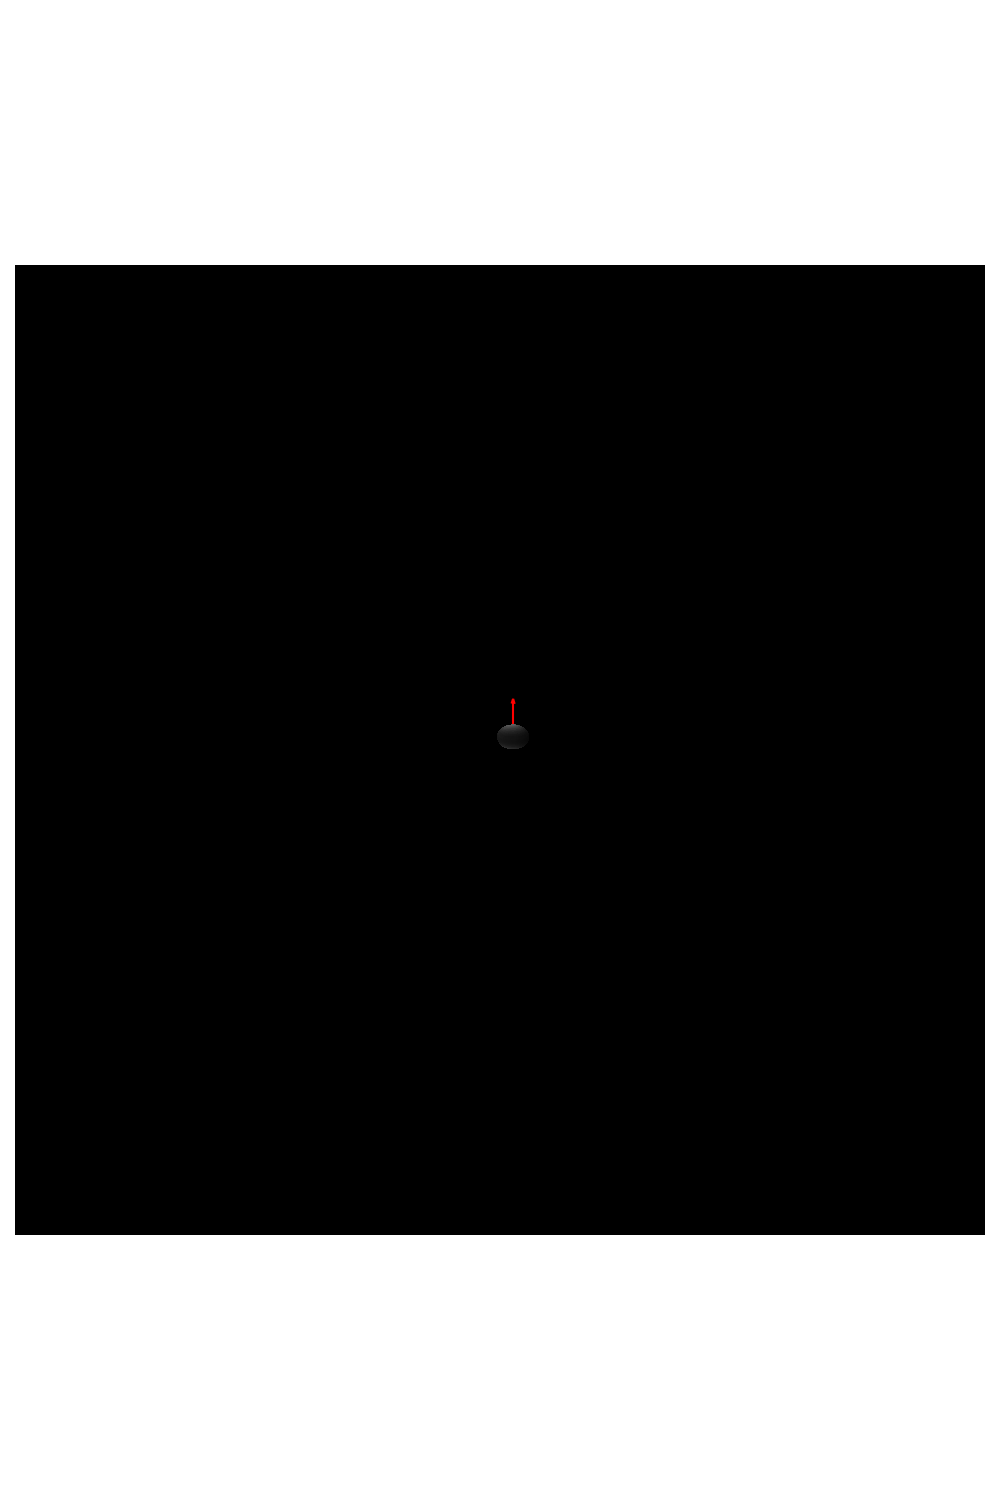

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LightSource
import matplotlib.cm as cm

# Create figure and axis
fig = plt.figure(figsize=(10, 15))
ax = fig.add_subplot(111, projection='3d')

# Plot static black hole at origin
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 50)
x_p = np.outer(np.cos(u), np.sin(v))
y_p = np.outer(np.sin(u), np.sin(v))
z_p = np.outer(np.ones(np.size(u)), np.cos(v))
base_color = np.full(x_p.shape, 0.3)
ls = LightSource(azdeg=315, altdeg=45)
rgb = ls.shade_rgb(np.dstack([base_color]*3), z_p, vert_exag=1.0, blend_mode='soft')
ax.plot_surface(0.65*x_p, 0.65*y_p, 0.65*z_p, facecolors=rgb, 
                rstride=1, cstride=1, antialiased=False, alpha=1)

# Add static spin indicator at origin
ax.quiver([0], [0], [0.75], [0], [0], [1.5], color='r', linewidths=1.5, arrow_length_ratio=0.2)

# Initialize dynamic elements
trajectory, = ax.plot([], [], [], 'r-', lw=1, alpha=0.7)
current_point, = ax.plot([], [], [], 'bo', markersize=2.5)
quiver_holder = [None]  # Container to hold the quiver object

# Configure plot aesthetics
ax.grid(False)
ax.set_axis_off()
ax.set_facecolor('black')
ax.view_init(elev=10)

# Set axis limits based on trajectory extent
max_range = max(np.max(np.abs(x)), np.max(np.abs(y)), np.max(np.abs(z))) * 1.1
ax.set_xlim(-max_range, max_range)
ax.set_ylim(-max_range, max_range)
ax.set_zlim(-max_range, max_range)

# Animation update function
def update(frame):
    # Update trajectory up to current frame
    trajectory.set_data(x[:frame], y[:frame])
    trajectory.set_3d_properties(z[:frame])
    
    # Update current position
    current_point.set_data([x[frame]], [y[frame]])
    current_point.set_3d_properties([z[frame]])
    
    # Remove previous quiver if it exists
    if quiver_holder[0] is not None:
        quiver_holder[0].remove()
    
    # Create new quiver with current spin vector
    new_quiver = ax.quiver(
        [x[frame]], [y[frame]], [z[frame]],
        [Sx[frame]], [Sy[frame]], [Sz[frame]],
        color='blue', arrow_length_ratio=0.25, alpha=1, linewidths=1.5
    )
    quiver_holder[0] = new_quiver
    
    return trajectory, current_point, new_quiver

# Create animation
ani = FuncAnimation(
    fig, update, frames=len(x), 
    interval=20, blit=False
)

plt.tight_layout()
plt.show()

# Save the animation
ani.save('blackhole_trajectory.gif', writer='pillow', fps=30, dpi=100)

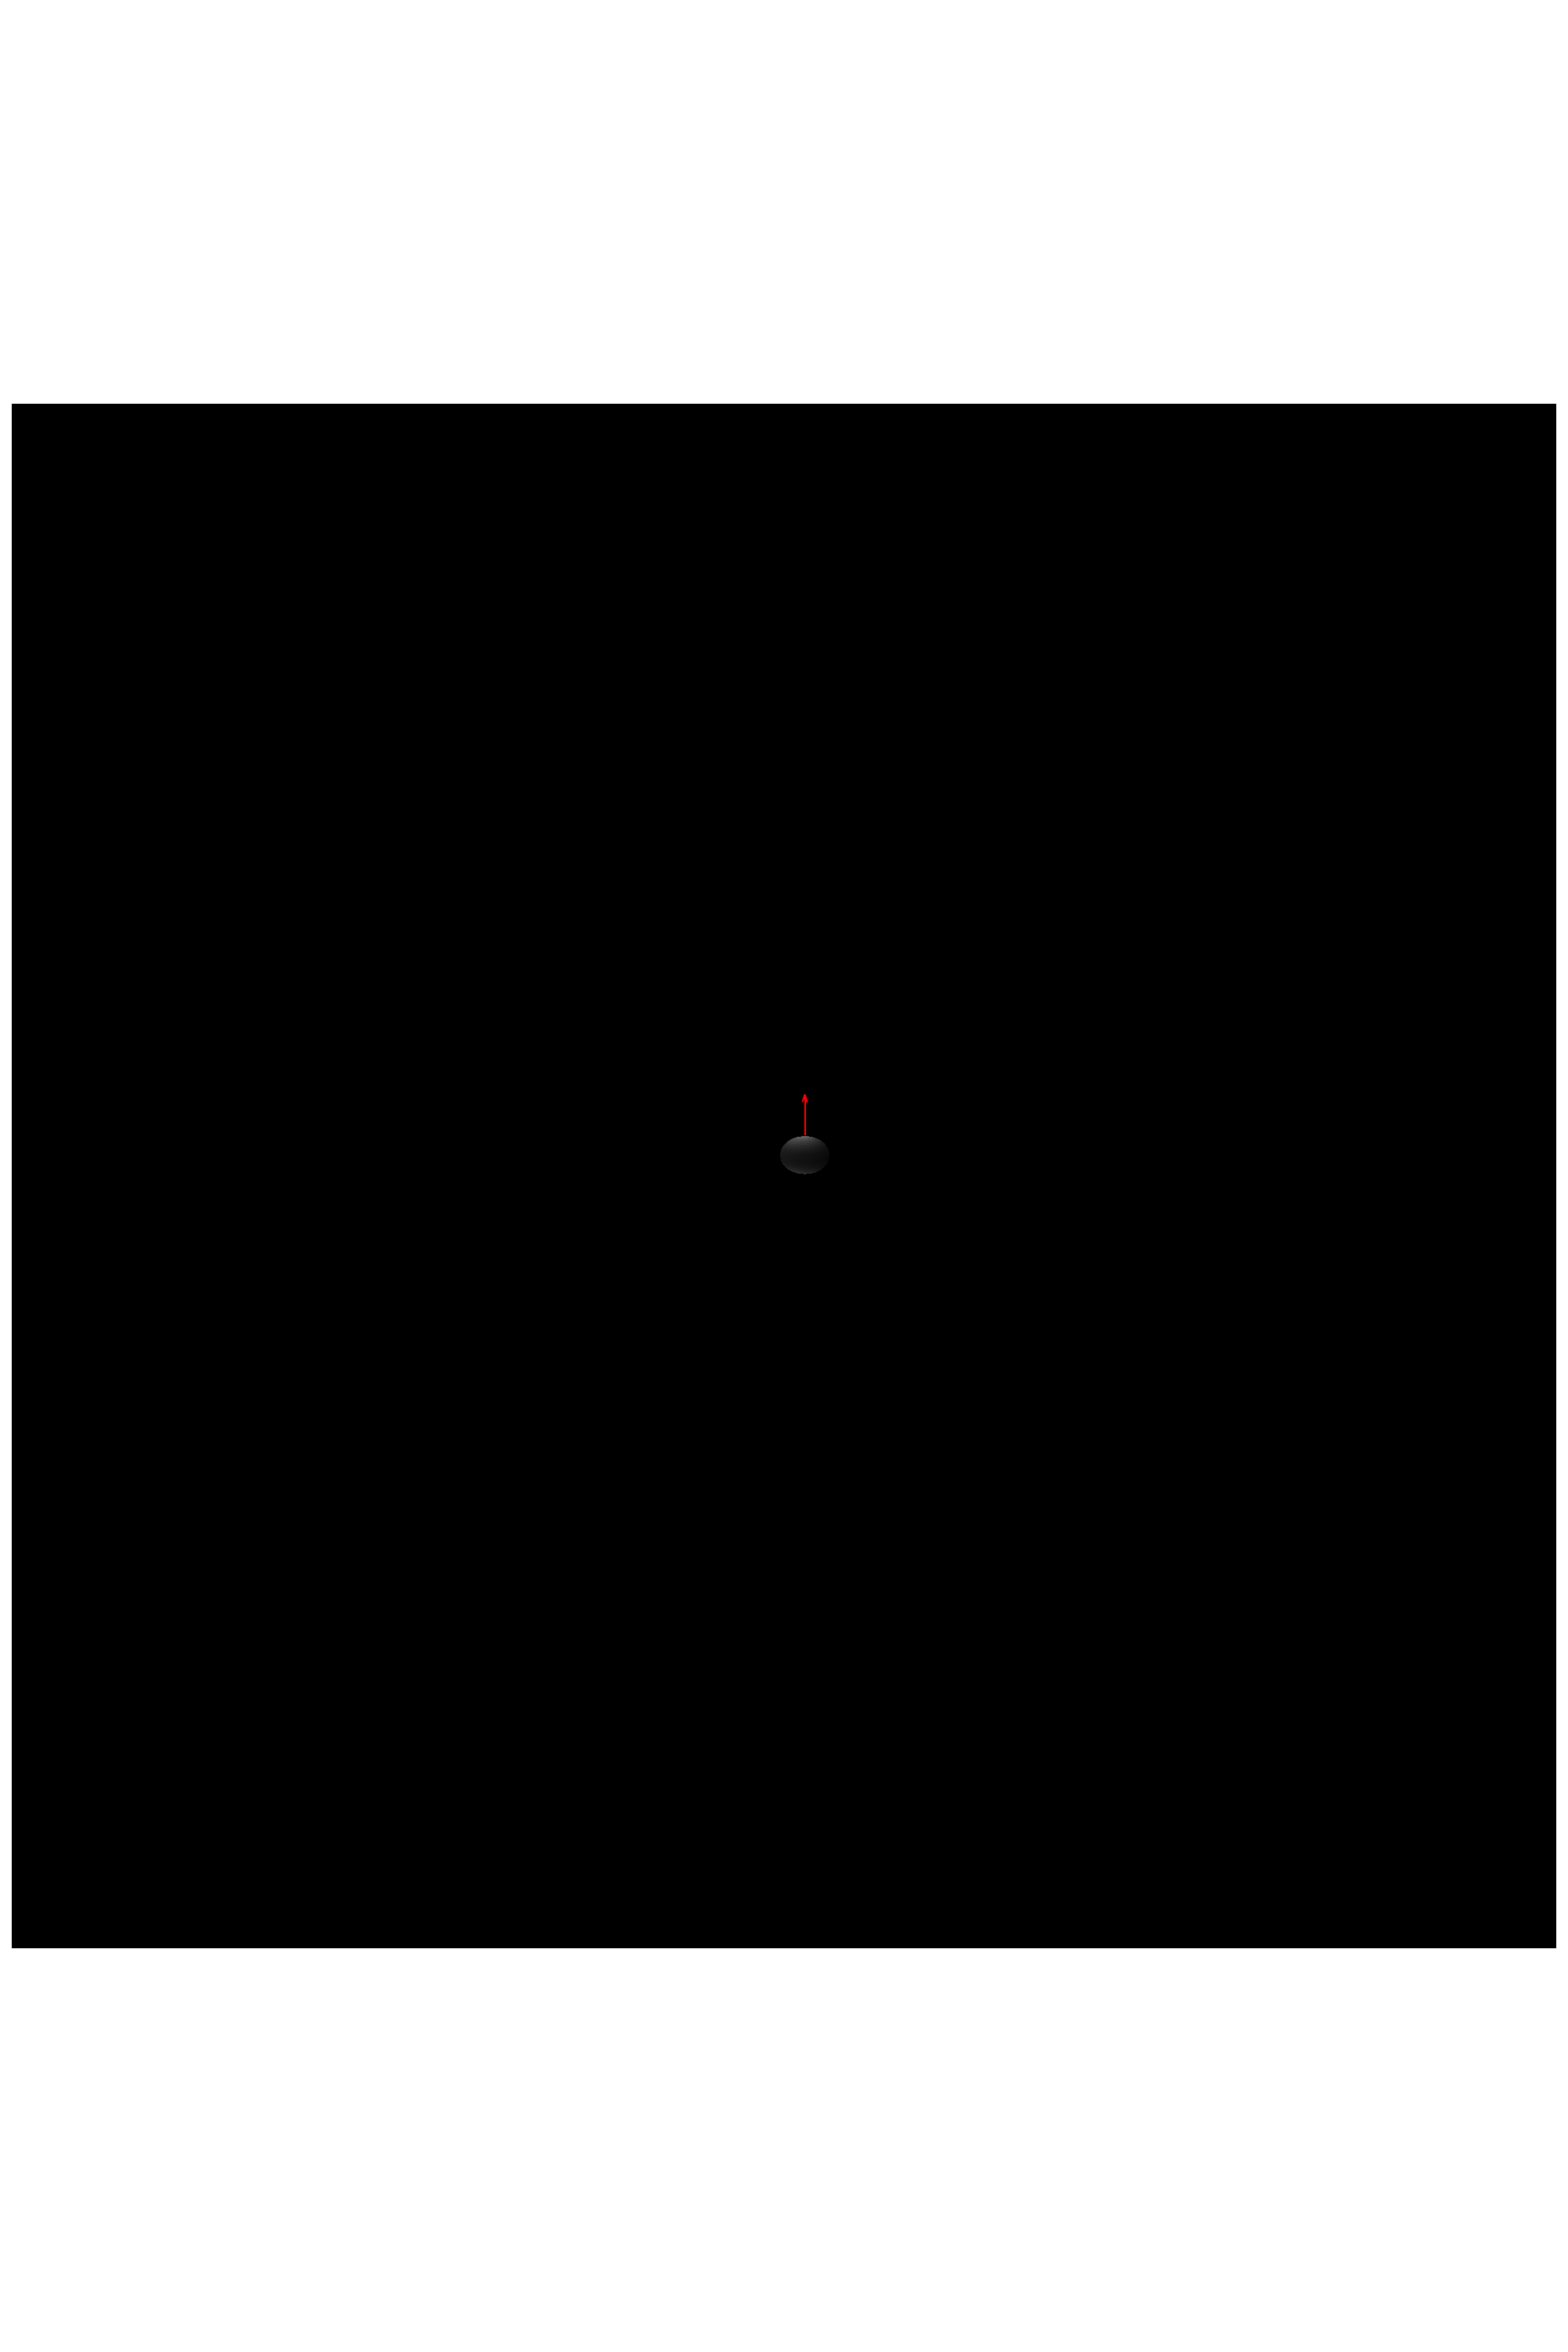

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LightSource

# Function to create a shaded sphere at a specific position
def create_shaded_sphere(ax, x0, y0, z0, radius, color=(0, 0.5, 0), alpha=1.0):
    """Create a shaded sphere at position (x0, y0, z0) with given radius and color"""
    u = np.linspace(0, 2 * np.pi, 20)  # Reduced resolution for performance
    v = np.linspace(0, np.pi, 10)
    x_p = np.outer(np.cos(u), np.sin(v))
    y_p = np.outer(np.sin(u), np.sin(v))
    z_p = np.outer(np.ones(np.size(u)), np.cos(v))
    
    # Create color array (RGB)
    base_color = np.zeros((x_p.shape[0], x_p.shape[1], 3))
    base_color[:,:,:] = color  # Apply RGB color
    
    # Apply lighting/shading
    ls = LightSource(azdeg=315, altdeg=45)
    shaded_rgb = ls.shade_rgb(base_color, z_p, vert_exag=1.0, blend_mode='soft')
    
    # Position and scale the sphere
    x_s = x0 + radius * x_p
    y_s = y0 + radius * y_p
    z_s = z0 + radius * z_p
    
    # Plot the surface
    return ax.plot_surface(x_s, y_s, z_s, facecolors=shaded_rgb, 
                          rstride=1, cstride=1, antialiased=False, alpha=alpha)

# Create figure and axis
fig = plt.figure(figsize=(20, 30))
ax = fig.add_subplot(111, projection='3d')

# Plot static black hole at origin
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 50)
x_p = np.outer(np.cos(u), np.sin(v))
y_p = np.outer(np.sin(u), np.sin(v))
z_p = np.outer(np.ones(np.size(u)), np.cos(v))
base_color = np.full(x_p.shape, 0.3)  # Dark gray
ls = LightSource(azdeg=315, altdeg=45)
rgb = ls.shade_rgb(np.dstack([base_color]*3), z_p, vert_exag=1.0, blend_mode='soft')
ax.plot_surface(0.65*x_p, 0.65*y_p, 0.65*z_p, facecolors=rgb, 
                rstride=1, cstride=1, antialiased=False, alpha=1)

# Add static spin indicator at origin
ax.quiver([0], [0], [0.75], [0], [0], [1.5], color='r', linewidths=1.5, arrow_length_ratio=0.2)

# Initialize dynamic elements
trajectory, = ax.plot([], [], [], 'r-', lw=1, alpha=0.7)
quivers = []  # List to store all quiver objects
current_sphere = [None]  # Container for the moving sphere artist

# Configure plot aesthetics
ax.grid(False)
ax.set_axis_off()
ax.set_facecolor('black')
ax.view_init(elev=10)

# Set axis limits based on trajectory extent
max_range = max(np.max(np.abs(x)), np.max(np.abs(y)), np.max(np.abs(z))) * 1.1
ax.set_xlim(-max_range, max_range)
ax.set_ylim(-max_range, max_range)
ax.set_zlim(-max_range, max_range)

# Animation update function
def update(frame):
    # Update trajectory up to current frame
    trajectory.set_data(x[:frame], y[:frame])
    trajectory.set_3d_properties(z[:frame])
    
    # Update moving sphere (remove old one if exists)
    if current_sphere[0] is not None:
        current_sphere[0].remove()
    
    # Create new shaded sphere at current position (green color)
    current_sphere[0] = create_shaded_sphere(
        ax, x[frame], y[frame], z[frame], 
        radius=0.1, color=(0.3, 0.3, 0.3), alpha=1.0
    )
    
    # Add new quiver at current position (persistent)
    q = ax.quiver(
        [x[frame]], [y[frame]], [z[frame]],
        [Sx[frame]], [Sy[frame]], [Sz[frame]],
        color='blue', arrow_length_ratio=0.25, alpha=0.7, linewidths=1.0
    )
    quivers.append(q)  # Store reference to prevent garbage collection
    
    # Return artists that need updating
    return [trajectory, current_sphere[0]] + quivers

# Create animation - use a step to reduce quiver density if needed
step = 1  # Set to higher value (e.g., 5) for fewer quivers
ani = FuncAnimation(
    fig, update, frames=range(0, len(x), step), 
    interval=20, blit=False, repeat=False
)

plt.tight_layout()
plt.show()

# Save the animation
ani.save('blackhole_trajectory_2.gif', writer='pillow', fps=20, dpi=100)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LightSource
import matplotlib.cm as cm

# Create figure and axis
fig = plt.figure(figsize=(10, 15))
ax = fig.add_subplot(111, projection='3d')

# Plot static black hole at origin
u = np.linspace(0, 2 * np.pi, 100)
v = np.linspace(0, np.pi, 50)
x_p = np.outer(np.cos(u), np.sin(v))
y_p = np.outer(np.sin(u), np.sin(v))
z_p = np.outer(np.ones(np.size(u)), np.cos(v))
base_color = np.full(x_p.shape, 0.3)
ls = LightSource(azdeg=315, altdeg=45)
rgb = ls.shade_rgb(np.dstack([base_color]*3), z_p, vert_exag=1.0, blend_mode='soft')
ax.plot_surface(0.65*x_p, 0.65*y_p, 0.65*z_p, facecolors=rgb, 
                rstride=1, cstride=1, antialiased=False, alpha=1)

# Add static spin indicator at origin
ax.quiver([0], [0], [0.75], [0], [0], [1.5], color='r', linewidths=1.5, arrow_length_ratio=0.2)

# Initialize dynamic elements
trajectory, = ax.plot([], [], [], 'r-', lw=1, alpha=0.7)
current_point, = ax.plot([], [], [], 'ro', markersize=3)
quiver_holder = [None]  # Container to hold the quiver object

# Configure plot aesthetics
ax.grid(False)
ax.set_axis_off()
ax.set_facecolor('black')
ax.view_init(elev=10)

# Set axis limits based on trajectory extent
max_range = max(np.max(np.abs(x)), np.max(np.abs(y)), np.max(np.abs(z))) * 1.1
ax.set_xlim(-max_range, max_range)
ax.set_ylim(-max_range, max_range)
ax.set_zlim(-max_range, max_range)

# Animation update function
def update(frame):
    # Update trajectory up to current frame
    trajectory.set_data(x[:frame], y[:frame])
    trajectory.set_3d_properties(z[:frame])
    
    # Update current position
    current_point.set_data([x[frame]], [y[frame]])
    current_point.set_3d_properties([z[frame]])
    
    # Remove previous quiver if it exists
    if quiver_holder[0] is not None:
        quiver_holder[0].remove()
    
    # Create new quiver with current spin vector
    new_quiver = ax.quiver(
        [x[frame]], [y[frame]], [z[frame]],
        [Sx[frame]], [Sy[frame]], [Sz[frame]],
        color='blue', arrow_length_ratio=0.25, alpha=1, linewidths=1.5
    )
    quiver_holder[0] = new_quiver
    
    return trajectory, current_point, new_quiver

# Create animation
ani = FuncAnimation(
    fig, update, frames=len(x), 
    interval=20, blit=False
)

plt.tight_layout()
plt.show()

# Save the animation
ani.save('blackhole_trajectory_3.gif', writer='pillow', fps=30, dpi=100)

In [114]:
# initialize trajectory class
traj = EMRIInspiral(func="pn5")
# run trajectory
dt = 10  # seconds
M = 1e+6
a = 0.9
mu = 30
p0 = 6 
e0 = 0.5
x0 = np.pi/3
phiK = 0.01  # azimuthal viewing angle
qS = 0.01 # polar sky angle
phiS = 0.01  # azimuthal viewing angle
dist = 0.1  # distance
T = 4  #0.03333 # years

t, p, e, x, Phi_phi, Phi_theta, Phi_r = traj(M, mu, a, p0, e0, xI0,
                                             Phi_phi0=0.0, Phi_theta0=0.0, Phi_r0=0.0, T=T)
E, L, Q = get_kerr_geo_constants_of_motion(a, p, e, x) 

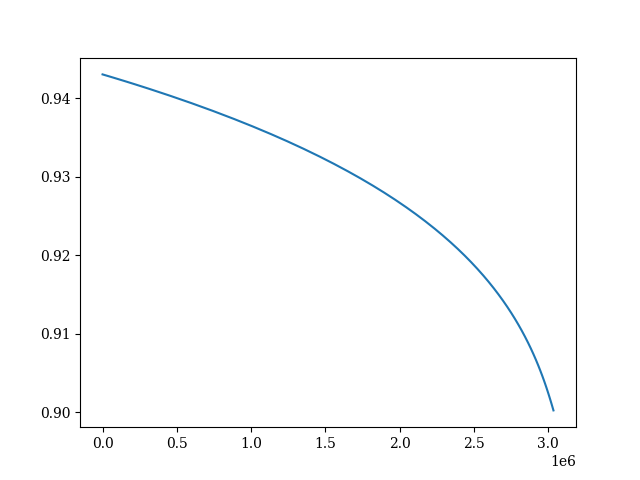

In [41]:
plt.figure()
plt.plot(t,E)

In [31]:
import numpy as np
from scipy.linalg import inv
from few.utils.constants import MTSUN_SI

class SpinningInspiral(SpinningOrbit):
    r"""Class for evolving GW-driven inspiral of spinning particles in Kerr spacetime.

    Parameters
    ----------
    a : double
        dimensionless angular momentum
    p0 : double
        initial semi-latus rectum
    e0 : double
        initial orbital eccentricity
    x0 : double
        initial cosine of orbital inclination
    s : double
        magnitude of spin vector
    theta_s : double
        polar angle of spin vector (radians)
    phi_s0 : double
        initial azimuthal phase of spin vector (radians)
    flux_function : callable
        Function that returns geodesic fluxes (dE_dt, dL_dt, dQ_dt)
        Signature: flux_function(M, a, E, L, Q) -> (dE_dt, dL_dt, dQ_dt)
    M : double
        mass of primary in solar masses
    mu : double
        mass of secondary in solar masses
    **kwargs
        Additional arguments passed to SpinningOrbit

    Attributes
    ----------
    flux_function : callable
        Geodesic flux function
    s_parallel : double
        Parallel spin component (constant)
    """

    def __init__(self, a, p0, e0, x0, s, theta_s, phi_s0, flux_function, M, mu, **kwargs):
        super().__init__(a, p0, e0, x0, s, theta_s, phi_s0, M=M, mu=mu, **kwargs)
        self.flux_function = flux_function
        self.s_parallel = s * np.cos(theta_s)  # Constant parallel spin component

    def compute_jacobian(self, E, L, Q):
        """Compute Jacobian matrix for transformation between constants.

        J = [[dE_tilde/dE, dE_tilde/dL, dE_tilde/dQ],
             [dL_tilde/dE, dL_tilde/dL, dL_tilde/dQ],
             [dQ_tilde/dE, dQ_tilde/dL, dQ_tilde/dQ]]

        Returns
        -------
        J : (3, 3) ndarray
            Jacobian matrix
        """
        s_parallel = self.s_parallel
        sqrtQ = np.sqrt(Q)
        Q32 = Q * sqrtQ  # Q^{3/2}

        # Derivatives for E_tilde
        dEtdE = 1 - s_parallel * E / sqrtQ
        dEtdL = 0
        dEtdQ = -s_parallel * (1 - E**2) / (2 * Q32)

        # Derivatives for L_tilde
        dLtdE = -s_parallel * L / (2 * sqrtQ)
        dLtdL = 1 - s_parallel * E / (2 * sqrtQ)
        dLtdQ = -s_parallel * (self.a - L*E/2) / (2 * Q32)

        # Derivatives for Q_tilde
        dQtdE = s_parallel * (-3*self.a**2 - Q) / sqrtQ
        dQtdL = s_parallel * 3*self.a / sqrtQ
        quad_term = 3*self.a*(L - self.a*E) - Q*E
        dQtdQ = 1 - s_parallel*E/sqrtQ - s_parallel*quad_term/(2*Q32)

        J = np.array([
            [dEtdE, dEtdL, dEtdQ],
            [dLtdE, dLtdL, dLtdQ],
            [dQtdE, dQtdL, dQtdQ]
        ])
        return J

    def evolve_constants(self, t_array):
        """Evolve constants of motion under radiation reaction.

        Parameters
        ----------
        t_array : array_like
            Time array in seconds

        Returns
        -------
        t_array : ndarray
            Input time array (seconds)
        E_spin : ndarray
            Specific energy for spinning particle
        L_spin : ndarray
            Specific angular momentum for spinning particle
        Q_spin : ndarray
            Carter constant for spinning particle
        E_nospin : ndarray
            Specific energy for non-spinning particle
        L_nospin : ndarray
            Specific angular momentum for non-spinning particle
        Q_nospin : ndarray
            Carter constant for non-spinning particle
        """
        # Convert time to natural units (t_nat = t / M)
        t_nat = t_array / (self.M * MTSUN_SI)
        dt_nat = np.diff(t_nat, prepend=t_nat[0])

        # Initialize arrays
        n = len(t_array)
        E_spin = np.zeros(n)
        L_spin = np.zeros(n)
        Q_spin = np.zeros(n)
        E_nospin = np.zeros(n)
        L_nospin = np.zeros(n)
        Q_nospin = np.zeros(n)

        # Initial conditions (spinning particle)
        E_spin[0] = self.E
        L_spin[0] = self.L
        Q_spin[0] = self.Q

        # Non-spinning particle has same initial conditions
        E_nospin[0] = self.E
        L_nospin[0] = self.L
        Q_nospin[0] = self.Q

        # Time evolution
        for i in range(1, n):
            dt = dt_nat[i]

            # ===== Spinning particle evolution =====
            # Compute shifted constants
            sqrtQ = np.sqrt(Q_spin[i-1])
            E_tilde = E_spin[i-1] + self.s_parallel * (1 - E_spin[i-1]**2) / (2 * sqrtQ)
            L_tilde = L_spin[i-1] + self.s_parallel * (self.a - L_spin[i-1]*E_spin[i-1]/2) / sqrtQ
            Q_tilde = Q_spin[i-1] + self.s_parallel * (3*self.a*(L_spin[i-1] - self.a*E_spin[i-1]) - Q_spin[i-1]*E_spin[i-1]) / sqrtQ

            # Get geodesic fluxes for virtual orbit
            dE_tilde_dt, dL_tilde_dt, dQ_tilde_dt = self.flux_function(
                self.M, self.a, E_tilde, L_tilde, Q_tilde
            )

            # Compute Jacobian at current state
            J = self.compute_jacobian(E_spin[i-1], L_spin[i-1], Q_spin[i-1])
            
            # Solve J * [dE_dt, dL_dt, dQ_dt]^T = [dE_tilde_dt, dL_tilde_dt, dQ_tilde_dt]^T
            dconstants_dt = np.linalg.solve(J, [dE_tilde_dt, dL_tilde_dt, dQ_tilde_dt])
            
            # Update spinning particle constants
            E_spin[i] = E_spin[i-1] + dconstants_dt[0] * dt
            L_spin[i] = L_spin[i-1] + dconstants_dt[1] * dt
            Q_spin[i] = Q_spin[i-1] + dconstants_dt[2] * dt

            # ===== Non-spinning particle evolution =====
            dE_dt, dL_dt, dQ_dt = self.flux_function(
                self.M, self.a, E_nospin[i-1], L_nospin[i-1], Q_nospin[i-1]
            )
            E_nospin[i] = E_nospin[i-1] + dE_dt * dt
            L_nospin[i] = L_nospin[i-1] + dL_dt * dt
            Q_nospin[i] = Q_nospin[i-1] + dQ_dt * dt

        return t_array, E_spin, L_spin, Q_spin, E_nospin, L_nospin, Q_nospin


/tmp/ipykernel_23684/1146789333.py:129: DeprecationWarning: 'scipy.integrate.cumtrapz' is deprecated in favour of 'scipy.integrate.cumulative_trapezoid' and will be removed in SciPy 1.14.0
  self.tau_g = cumtrapz(np.sqrt(1 - self.E_vg**2), self.t_vg, initial=0)


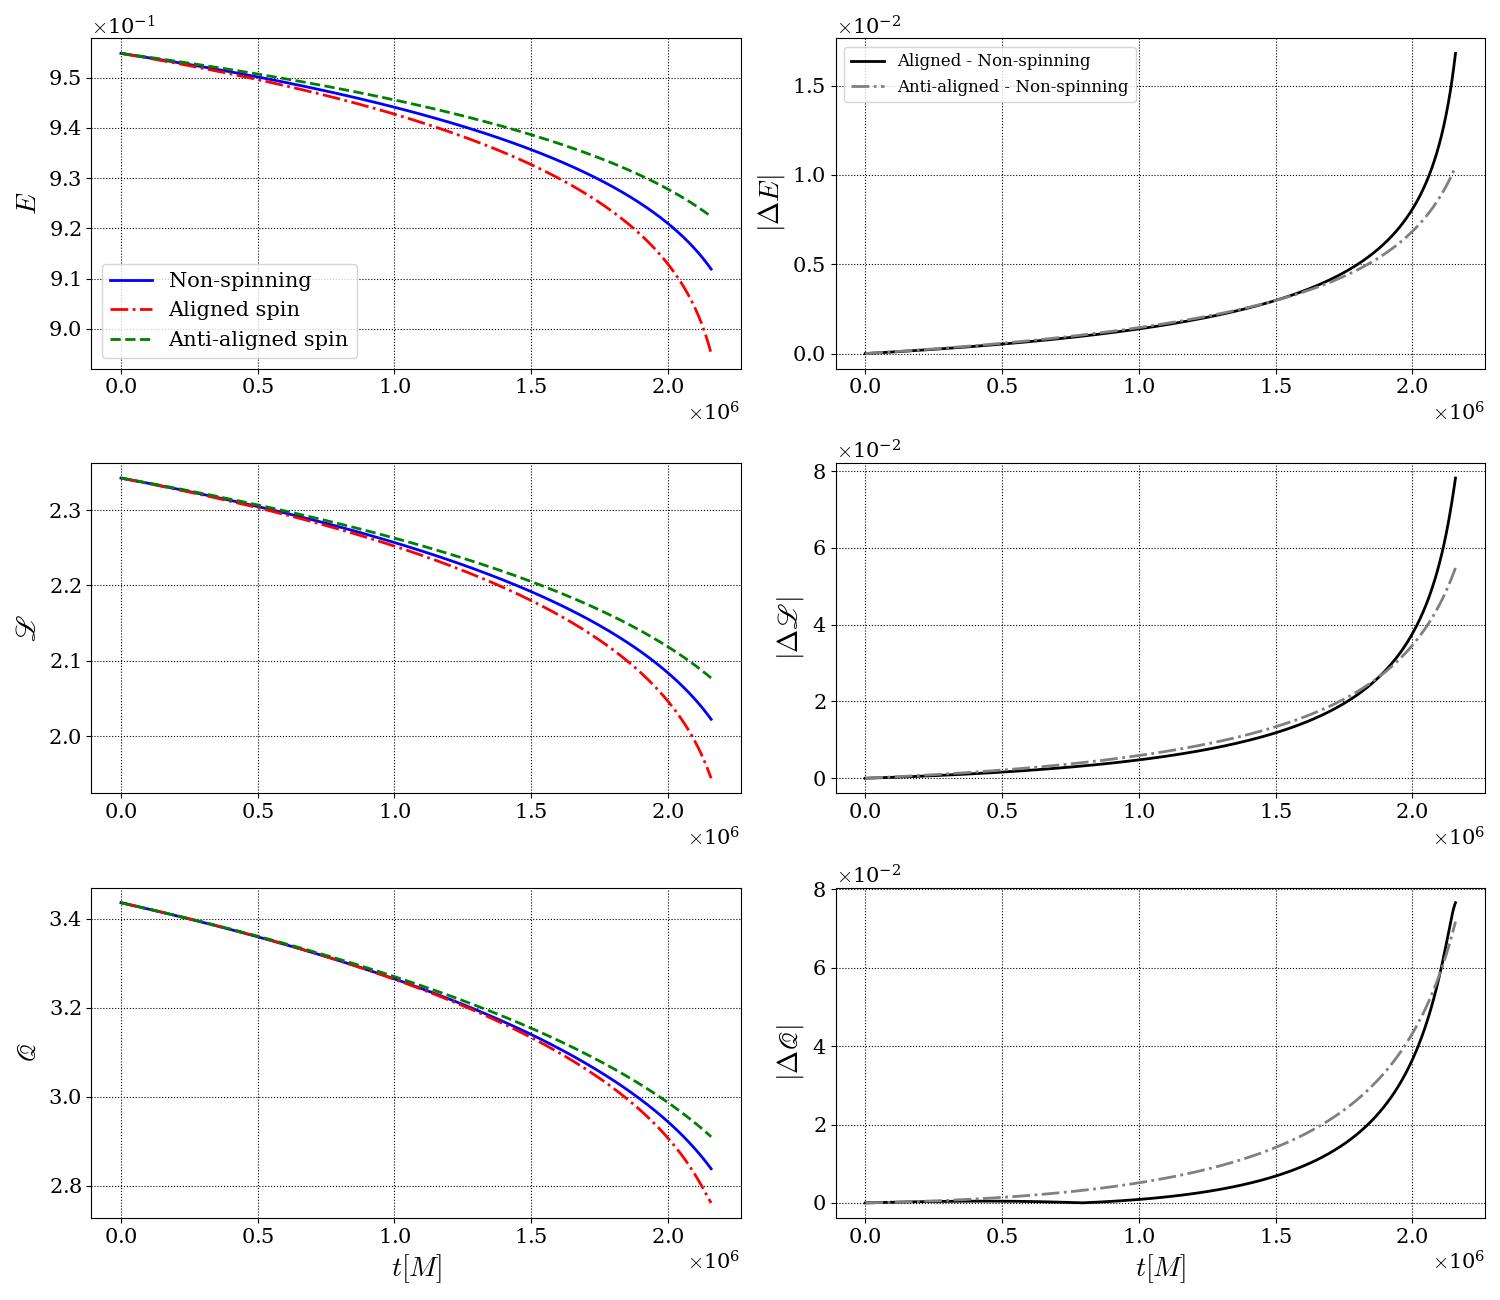

In [89]:
import numpy as np
import matplotlib.pyplot as plt
from few.trajectory.inspiral import EMRIInspiral
from few.utils.utility import get_kerr_geo_constants_of_motion, ELQ_to_pex
from few.utils.constants import MTSUN_SI
from scipy.optimize import fsolve
from scipy.interpolate import interp1d
from scipy.integrate import cumtrapz

class SpinningInspiral:
    r"""Class for spinning inspirals using virtual geodesic transformation.
    
    Parameters
    ----------
    a : float
        Dimensionless spin parameter of primary black hole
    p0 : float
        Initial semi-latus rectum
    e0 : float
        Initial eccentricity
    x0 : float
        Initial cosine of inclination
    s : float
        Magnitude of spin vector (μM units)
    theta_s : float
        Polar angle of spin vector (radians)
    M : float
        Mass of primary in solar masses
    mu : float
        Mass of secondary in solar masses
    T : float
        Total evolution time in years
    dt : float, optional
        Time step in seconds, default=10
    flux_model : str, optional
        Flux model for EMRIInspiral, default="pn5"
    """
    
    def __init__(self, a, p0, e0, x0, s, theta_s, M, mu, T, dt=10, flux_model="pn5"):
        self.a = a
        self.M = M
        self.mu = mu
        self.s = s
        self.theta_s = theta_s
        self.s_parallel = s * np.cos(theta_s)
        self.s_perp = s * np.sin(theta_s)
        self.T = T * 365.25 * 24 * 3600  # years to seconds
        self.dt = dt
        
        # Step 1: Compute non-spinning trajectory
        self.compute_non_spinning_trajectory(a, p0, e0, x0, M, mu, flux_model)
        
        # Step 2: Compute virtual geodesic constants at initial time
        self.compute_virtual_geodesic_constants()
        
        # Step 3: Compute virtual geodesic trajectory
        self.compute_virtual_geodesic_trajectory(flux_model)
        
        # Step 4: Compute spinning particle constants from virtual geodesic
        self.compute_spinning_constants()
        
        # Step 5: Compute actual coordinate time
        self.compute_actual_time()

    def compute_non_spinning_trajectory(self, a, p0, e0, x0, M, mu, flux_model):
        """Compute non-spinning reference trajectory"""
        traj = EMRIInspiral(func=flux_model)
        
        # Run trajectory - capture all 7 outputs
        result = traj(
            M, mu, a, p0, e0, x0,
            Phi_phi0=0.0, Phi_theta0=0.0, Phi_r0=0.0,
            T=self.T, dt=self.dt
        )
        self.t_ns, self.p_ns, self.e_ns, self.x_ns, self.phi_phi_ns, self.phi_theta_ns, self.phi_r_ns = result
        
        # Compute constants of motion
        self.E_ns, self.L_ns, self.Q_ns = get_kerr_geo_constants_of_motion(
            a, self.p_ns, self.e_ns, self.x_ns
        )
        
        # Compute separation constant K (paper) from Q (code)
        self.K_ns = self.Q_ns + (self.L_ns - self.a*self.E_ns)**2

    def compute_virtual_geodesic_constants(self):
        """Compute virtual geodesic constants at initial time using Eq. (22)"""
        # Initial constants from non-spinning trajectory
        E0 = self.E_ns[0]
        L0 = self.L_ns[0]
        K0 = self.K_ns[0]
        s_parallel = self.s_parallel
        sqrtK = np.sqrt(K0)
        
        # Apply Eq. (22) transformation
        self.E_tilde0 = E0 + s_parallel * (1 - E0**2) / (2 * sqrtK)
        self.L_tilde0 = L0 + s_parallel * (self.a - L0*E0/2) / sqrtK
        self.K_tilde0 = K0 + s_parallel * (3*self.a*(L0 - self.a*E0) - K0*E0) / sqrtK
        
        # Convert to Q for virtual geodesic
        self.Q_tilde0 = self.K_tilde0 - (self.L_tilde0 - self.a*self.E_tilde0)**2

    def compute_virtual_geodesic_trajectory(self, flux_model):
        """Compute trajectory for virtual geodesic"""
        # Convert constants to orbital parameters
        p0_tilde, e0_tilde, x0_tilde = ELQ_to_pex(
            self.a, self.E_tilde0, self.L_tilde0, self.Q_tilde0
        )
        
        # Run trajectory for virtual geodesic - capture all 7 outputs
        traj = EMRIInspiral(func=flux_model)
        result = traj(
            self.M, self.mu, self.a, 
            p0_tilde, e0_tilde, x0_tilde,
            Phi_phi0=0.0, Phi_theta0=0.0, Phi_r0=0.0,
            T=self.T, dt=self.dt
        )
        self.t_vg, self.p_vg, self.e_vg, self.x_vg, self.phi_phi_vg, self.phi_theta_vg, self.phi_r_vg = result
        
        # Compute constants for virtual geodesic
        self.E_vg, self.L_vg, self.Q_vg = get_kerr_geo_constants_of_motion(
            self.a, self.p_vg, self.e_vg, self.x_vg
        )
        
        # Compute separation constant K̃ for virtual geodesic
        self.K_vg = self.Q_vg + (self.L_vg - self.a*self.E_vg)**2
        
        # Compute proper time τ_g for virtual geodesic
        # Approximate using dt and energy
        self.tau_g = cumtrapz(np.sqrt(1 - self.E_vg**2), self.t_vg, initial=0)

    def compute_spinning_constants(self):
        """Invert Eq. (22) to get spinning particle constants from virtual geodesic"""
        self.E_spin = np.zeros_like(self.E_vg)
        self.L_spin = np.zeros_like(self.L_vg)
        self.K_spin = np.zeros_like(self.K_vg)
        
        # Initial guess (spinning particle constants should be close to non-spinning)
        E_guess = self.E_ns[0]
        L_guess = self.L_ns[0]
        K_guess = self.K_ns[0]
        
        for i in range(len(self.t_vg)):
            # Virtual geodesic constants
            E_tilde = self.E_vg[i]
            L_tilde = self.L_vg[i]
            K_tilde = self.K_vg[i]
            
            # Solve for spinning particle constants
            solution = fsolve(
                self._spinning_equations, 
                [E_guess, L_guess, K_guess],
                args=(E_tilde, L_tilde, K_tilde)
            )
            
            # Store solution
            self.E_spin[i] = solution[0]
            self.L_spin[i] = solution[1]
            self.K_spin[i] = solution[2]
            
            # Update guess for next iteration
            E_guess, L_guess, K_guess = solution
        
        # Convert K to Q for spinning particle
        self.Q_spin = self.K_spin - (self.L_spin - self.a*self.E_spin)**2

    def _spinning_equations(self, x, E_tilde, L_tilde, K_tilde):
        """Equations to solve for spinning particle constants (inverse of Eq. 22)"""
        E, L, K = x
        sqrtK = np.sqrt(K)
        s_parallel = self.s_parallel
        
        eq1 = E + s_parallel * (1 - E**2) / (2 * sqrtK) - E_tilde
        eq2 = L + s_parallel * (self.a - L*E/2) / sqrtK - L_tilde
        eq3 = K + s_parallel * (3*self.a*(L - self.a*E) - K*E) / sqrtK - K_tilde
        
        return [eq1, eq2, eq3]
    
    def displacement_vector_component(self, i):
        """Compute δt component of displacement vector at index i (simplified)"""
        # For simplicity, we'll approximate δt as 0
        # In a full implementation, this would use Eqs. (S12-S14)
        return 0
    
    def compute_actual_time(self):
        """Compute actual coordinate time using Eq. (25a)"""
        # For spinning trajectory: t = t̃ - (3s_∥)/(2√K) τ_g - δt
        avg_sqrtK = np.sqrt(np.mean(self.K_spin))
        self.t_spin_actual = (self.t_vg - 
                             (3 * self.s_parallel / (2 * avg_sqrtK)) * self.tau_g - 
                             np.array([self.displacement_vector_component(i) for i in range(len(self.t_vg))]))
        
        # For non-spinning trajectory, actual time is just t_ns
        self.t_ns_actual = self.t_ns

# New function to run and compare aligned and anti-aligned cases
def run_and_compare(a, p0, e0, x0, s, M, mu, T, dt=10, flux_model="pn5"):
    """Run aligned and anti-aligned spin cases and compare results"""
    # Run aligned case (theta_s = 0)
    aligned = SpinningInspiral(a, p0, e0, x0, s, 0, M, mu, T, dt, flux_model)
    
    # Run anti-aligned case (theta_s = pi)
    anti = SpinningInspiral(a, p0, e0, x0, s, np.pi, M, mu, T, dt, flux_model)
    
    # Get non-spinning trajectory from aligned case (same for both)
    t_ns_actual = aligned.t_ns_actual
    E_ns = aligned.E_ns
    L_ns = aligned.L_ns
    Q_ns = aligned.Q_ns
    
    # Get aligned spin results
    t_aligned = aligned.t_spin_actual
    E_aligned = aligned.E_spin
    L_aligned = aligned.L_spin
    Q_aligned = aligned.Q_spin
    
    # Get anti-aligned spin results
    t_anti = anti.t_spin_actual
    E_anti = anti.E_spin
    L_anti = anti.L_spin
    Q_anti = anti.Q_spin
    
    # Convert time to natural units (t/M)
    t_nat_ns = t_ns_actual / (M * MTSUN_SI)
    t_nat_aligned = t_aligned / (M * MTSUN_SI)
    t_nat_anti = t_anti / (M * MTSUN_SI)
    
    # Create a common time grid
    t_min = max(t_nat_ns.min(), t_nat_aligned.min(), t_nat_anti.min())
    t_max = min(t_nat_ns.max(), t_nat_aligned.max(), t_nat_anti.max())
    t_common = np.linspace(t_min, t_max, 1000)
    
    # Interpolate constants to common time grid
    E_ns_interp = interp1d(t_nat_ns, E_ns, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    L_ns_interp = interp1d(t_nat_ns, L_ns, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    Q_ns_interp = interp1d(t_nat_ns, Q_ns, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    
    E_aligned_interp = interp1d(t_nat_aligned, E_aligned, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    L_aligned_interp = interp1d(t_nat_aligned, L_aligned, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    Q_aligned_interp = interp1d(t_nat_aligned, Q_aligned, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    
    E_anti_interp = interp1d(t_nat_anti, E_anti, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    L_anti_interp = interp1d(t_nat_anti, L_anti, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    Q_anti_interp = interp1d(t_nat_anti, Q_anti, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    
    # Compute differences
    diff_E_aligned = np.abs(E_aligned_interp - E_ns_interp)
    diff_L_aligned = np.abs(L_aligned_interp - L_ns_interp)
    diff_Q_aligned = np.abs(Q_aligned_interp - Q_ns_interp)
    
    diff_E_anti = np.abs(E_anti_interp - E_ns_interp)
    diff_L_anti = np.abs(L_anti_interp - L_ns_interp)
    diff_Q_anti = np.abs(Q_anti_interp - Q_ns_interp)
    
    # Plot results
    plt.figure(figsize=(15, 13))
    plt.rc('xtick', labelsize=15)
    plt.rc('ytick', labelsize=15)
    
    # Energy plot
    plt.subplot(321)
    plt.plot(t_common, E_ns_interp, 'b-', label='Non-spinning', lw=2)
    plt.plot(t_common, E_aligned_interp, 'r-.', label='Aligned spin', lw=2)
    plt.plot(t_common, E_anti_interp, 'g--', label='Anti-aligned spin', lw=2)
    plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0), useMathText=True)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.ylabel('$E$', fontsize=20)
    plt.grid(linestyle=":", color="black")
    plt.legend(fontsize=15)
    
    # Angular momentum plot
    plt.subplot(323)
    plt.plot(t_common, L_ns_interp, 'b-', lw=2)
    plt.plot(t_common, L_aligned_interp, 'r-.', lw=2)
    plt.plot(t_common, L_anti_interp, 'g--', lw=2)
    plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0), useMathText=True)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.ylabel('$\mathscr{L}$', fontsize=20)
    plt.grid(linestyle=":", color="black")
    
    # Carter constant plot
    plt.subplot(325)
    plt.plot(t_common, Q_ns_interp, 'b-', lw=2)
    plt.plot(t_common, Q_aligned_interp, 'r-.', lw=2)
    plt.plot(t_common, Q_anti_interp, 'g--', lw=2)
    plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0), useMathText=True)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.ylabel('$\mathscr{Q}$', fontsize=20)
    plt.xlabel('$t [M]$', fontsize=20)
    plt.grid(linestyle=":", color="black")
    
    # Energy differences plot
    plt.subplot(322)
    plt.plot(t_common, diff_E_aligned, 'k-', label='Aligned - Non-spinning', lw=2)
    plt.plot(t_common, diff_E_anti, 'gray', linestyle='-.', label='Anti-aligned - Non-spinning', lw=2)
    plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0), useMathText=True)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.ylabel('$|\Delta E|$', fontsize=20)
    plt.grid(linestyle=":", color="black")
    plt.legend(fontsize=12)
    
    # Angular momentum differences plot
    plt.subplot(324)
    plt.plot(t_common, diff_L_aligned, 'k-', lw=2)
    plt.plot(t_common, diff_L_anti, 'gray', linestyle='-.', lw=2)
    plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0), useMathText=True)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.ylabel('$|\Delta\mathscr{L}|$', fontsize=20)
    plt.grid(linestyle=":", color="black")
    
    # Carter constant differences plot
    plt.subplot(326)
    plt.plot(t_common, diff_Q_aligned, 'k-', lw=2)
    plt.plot(t_common, diff_Q_anti, 'gray', linestyle='-.', lw=2)
    plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0), useMathText=True)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.ylabel('$|\Delta\mathscr{Q}|$', fontsize=20)
    plt.xlabel('$t [M]$', fontsize=20)
    plt.grid(linestyle=":", color="black")
    
    plt.tight_layout()
    plt.savefig("ELQ_evolution_spin_comparison.pdf")
    plt.savefig("ELQ_evolution_spin_comparison.png")
    plt.show()

# Example usage
if __name__ == "__main__":
    # Parameters
    a = 0.9
    p0 = 6.0
    e0 = 0.65
    x0 = np.pi/4
    s = 0.1
    M = 1e6  # Solar masses
    mu = 10   # Solar masses
    T = 1   # Years
    
    # Run and compare aligned and anti-aligned cases
    run_and_compare(a, p0, e0, x0, s, M, mu, T)

/tmp/ipykernel_946/809211173.py:133: DeprecationWarning: 'scipy.integrate.cumtrapz' is deprecated in favour of 'scipy.integrate.cumulative_trapezoid' and will be removed in SciPy 1.14.0
  self.tau_g = cumtrapz(np.sqrt(1 - self.E_vg**2), self.t_vg, initial=0)


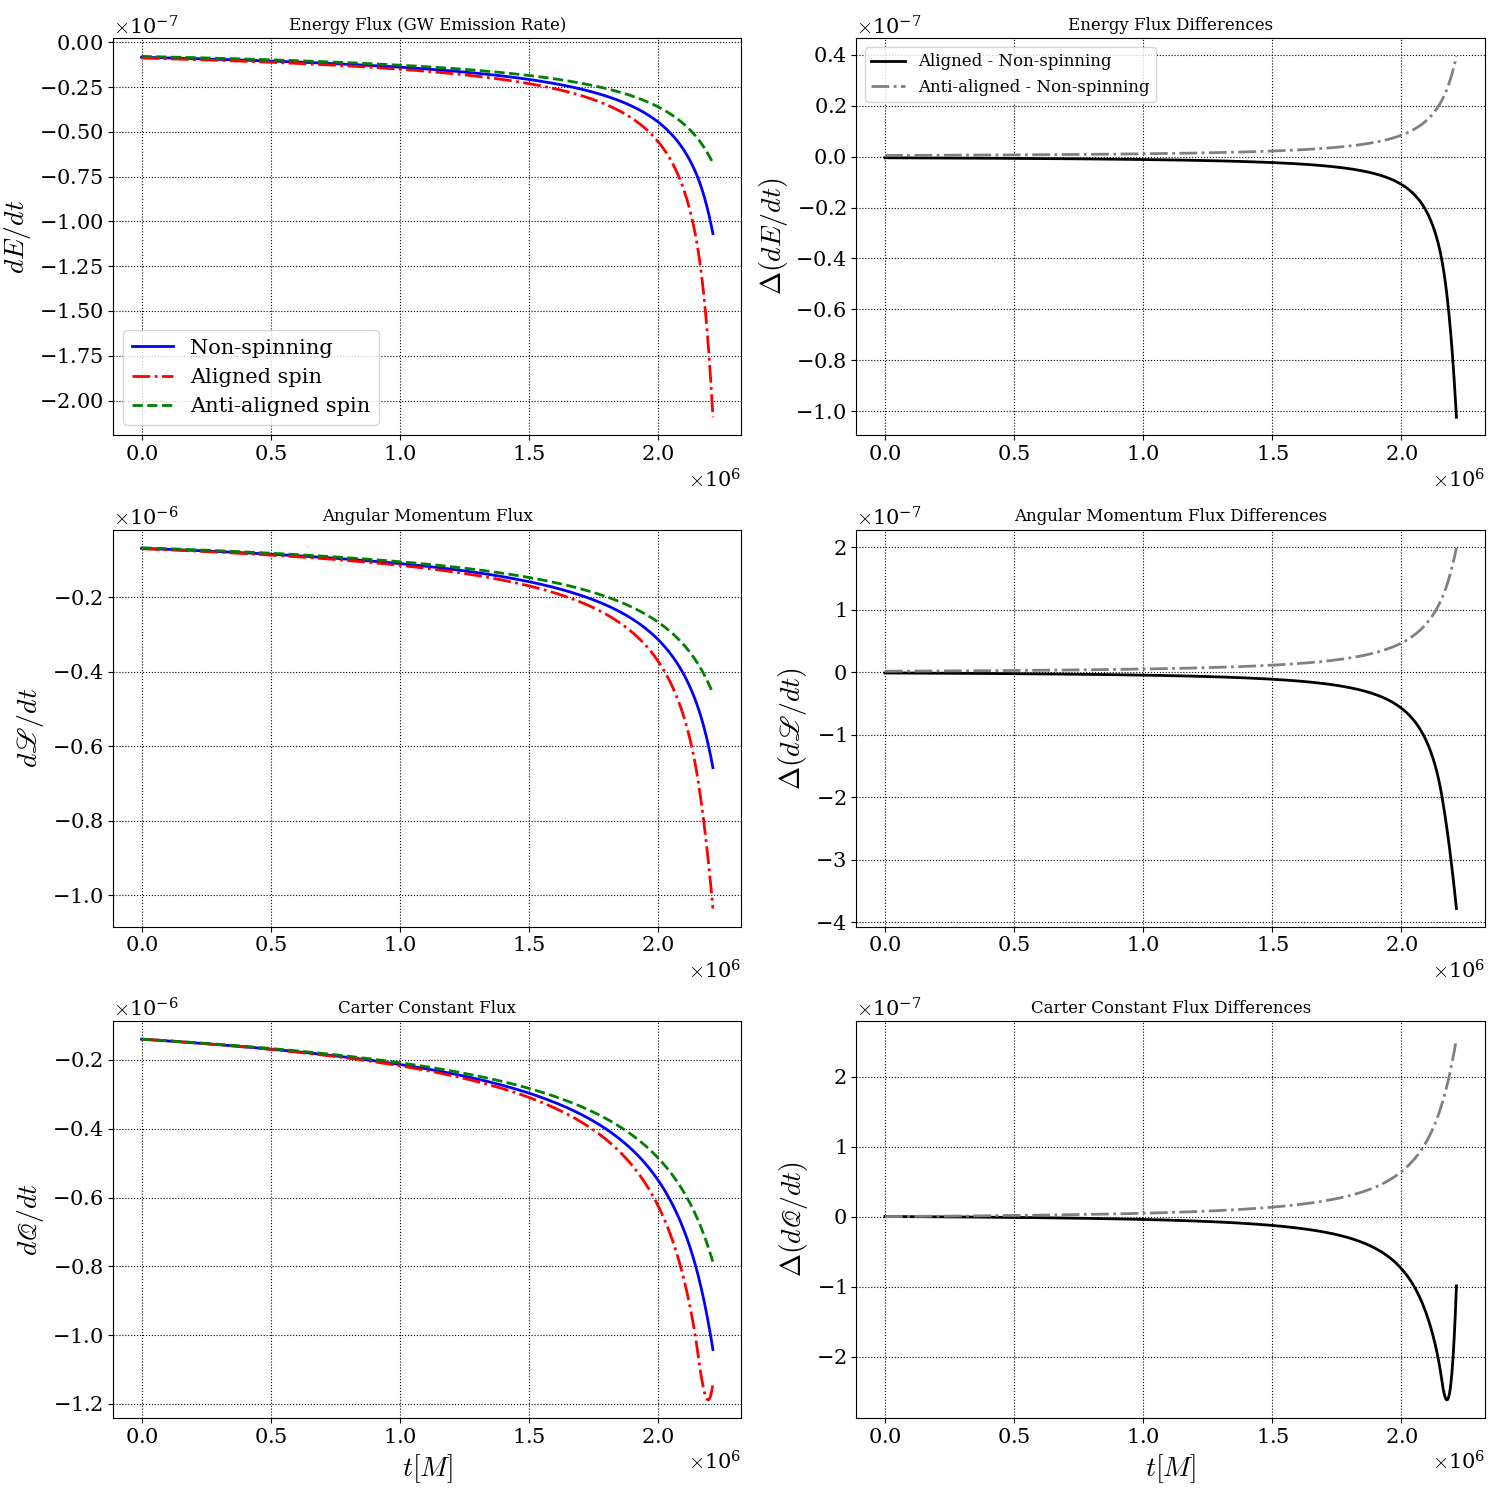

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from few.trajectory.inspiral import EMRIInspiral
from few.utils.utility import get_kerr_geo_constants_of_motion, ELQ_to_pex
from few.utils.constants import MTSUN_SI
from scipy.optimize import fsolve
from scipy.interpolate import interp1d
from scipy.integrate import cumtrapz
from scipy.signal import savgol_filter

class SpinningInspiral:
    r"""Class for spinning inspirals using virtual geodesic transformation.
    
    Parameters
    ----------
    a : float
        Dimensionless spin parameter of primary black hole
    p0 : float
        Initial semi-latus rectum
    e0 : float
        Initial eccentricity
    x0 : float
        Initial cosine of inclination
    s : float
        Magnitude of spin vector (μM units)
    theta_s : float
        Polar angle of spin vector (radians)
    M : float
        Mass of primary in solar masses
    mu : float
        Mass of secondary in solar masses
    T : float
        Total evolution time in years
    dt : float, optional
        Time step in seconds, default=10
    flux_model : str, optional
        Flux model for EMRIInspiral, default="pn5"
    """
    

    def __init__(self, a, p0, e0, x0, s, theta_s, M, mu, T, dt=10, flux_model="pn5"):
        self.a = a
        self.M = M
        self.mu = mu
        self.s = s
        self.theta_s = theta_s
        self.s_parallel = s * np.cos(theta_s)
        self.s_perp = s * np.sin(theta_s)
        self.T = T * 365.25 * 24 * 3600  # years to seconds
        self.dt = dt
        
        # Step 1: Compute non-spinning trajectory
        self.compute_non_spinning_trajectory(a, p0, e0, x0, M, mu, flux_model)
        
        # Step 2: Compute virtual geodesic constants at initial time
        self.compute_virtual_geodesic_constants()
        
        # Step 3: Compute virtual geodesic trajectory
        self.compute_virtual_geodesic_trajectory(flux_model)
        
        # Step 4: Compute spinning particle constants from virtual geodesic
        self.compute_spinning_constants()
        
        # Step 5: Compute actual coordinate time
        self.compute_actual_time()

    def compute_non_spinning_trajectory(self, a, p0, e0, x0, M, mu, flux_model):
        """Compute non-spinning reference trajectory"""
        traj = EMRIInspiral(func=flux_model)
        
        # Run trajectory - capture all 7 outputs

        result = traj(
            M, mu, a, p0, e0, x0,
            Phi_phi0=0.0, Phi_theta0=0.0, Phi_r0=0.0,
            T=self.T, dt=self.dt
        )
        self.t_ns, self.p_ns, self.e_ns, self.x_ns, self.phi_phi_ns, self.phi_theta_ns, self.phi_r_ns = result
        
        # Compute constants of motion
        self.E_ns, self.L_ns, self.Q_ns = get_kerr_geo_constants_of_motion(
            a, self.p_ns, self.e_ns, self.x_ns
        )
        
        # Compute separation constant K (paper) from Q (code)
        self.K_ns = self.Q_ns + (self.L_ns - self.a*self.E_ns)**2

    def compute_virtual_geodesic_constants(self):
        """Compute virtual geodesic constants at initial time using Eq. (22)"""
        # Initial constants from non-spinning trajectory
        E0 = self.E_ns[0]
        L0 = self.L_ns[0]
        K0 = self.K_ns[0]
        s_parallel = self.s_parallel
        sqrtK = np.sqrt(K0)
        
        # Apply Eq. (22) transformation
        self.E_tilde0 = E0 + s_parallel * (1 - E0**2) / (2 * sqrtK)
        self.L_tilde0 = L0 + s_parallel * (self.a - L0*E0/2) / sqrtK
        self.K_tilde0 = K0 + s_parallel * (3*self.a*(L0 - self.a*E0) - K0*E0) / sqrtK
        
        # Convert to Q for virtual geodesic
        self.Q_tilde0 = self.K_tilde0 - (self.L_tilde0 - self.a*self.E_tilde0)**2

    def compute_virtual_geodesic_trajectory(self, flux_model):

        """Compute trajectory for virtual geodesic"""
        # Convert constants to orbital parameters
        p0_tilde, e0_tilde, x0_tilde = ELQ_to_pex(
            self.a, self.E_tilde0, self.L_tilde0, self.Q_tilde0
        )
        
        # Run trajectory for virtual geodesic - capture all 7 outputs
        traj = EMRIInspiral(func=flux_model)
        result = traj(
            self.M, self.mu, self.a, 
            p0_tilde, e0_tilde, x0_tilde,
            Phi_phi0=0.0, Phi_theta0=0.0, Phi_r0=0.0,
            T=self.T, dt=self.dt
        )
        self.t_vg, self.p_vg, self.e_vg, self.x_vg, self.phi_phi_vg, self.phi_theta_vg, self.phi_r_vg = result
        
        # Compute constants for virtual geodesic
        self.E_vg, self.L_vg, self.Q_vg = get_kerr_geo_constants_of_motion(
            self.a, self.p_vg, self.e_vg, self.x_vg
        )
        
        # Compute separation constant K̃ for virtual geodesic
        self.K_vg = self.Q_vg + (self.L_vg - self.a*self.E_vg)**2
        
        # Compute proper time τ_g for virtual geodesic
        # Approximate using dt and energy
        self.tau_g = cumtrapz(np.sqrt(1 - self.E_vg**2), self.t_vg, initial=0)

    def compute_spinning_constants(self):
        """Invert Eq. (22) to get spinning particle constants from virtual geodesic"""
        self.E_spin = np.zeros_like(self.E_vg)
        self.L_spin = np.zeros_like(self.L_vg)

        self.K_spin = np.zeros_like(self.K_vg)
        
        # Initial guess (spinning particle constants should be close to non-spinning)
        E_guess = self.E_ns[0]
        L_guess = self.L_ns[0]
        K_guess = self.K_ns[0]
        
        for i in range(len(self.t_vg)):
            # Virtual geodesic constants
            E_tilde = self.E_vg[i]
            L_tilde = self.L_vg[i]
            K_tilde = self.K_vg[i]
            
            # Solve for spinning particle constants
            solution = fsolve(
                self._spinning_equations, 
                [E_guess, L_guess, K_guess],
                args=(E_tilde, L_tilde, K_tilde)
            )
            
            # Store solution
            self.E_spin[i] = solution[0]
            self.L_spin[i] = solution[1]
            self.K_spin[i] = solution[2]
            
            # Update guess for next iteration
            E_guess, L_guess, K_guess = solution
        
        # Convert K to Q for spinning particle
        self.Q_spin = self.K_spin - (self.L_spin - self.a*self.E_spin)**2

    def _spinning_equations(self, x, E_tilde, L_tilde, K_tilde):
        """Equations to solve for spinning particle constants (inverse of Eq. 22)"""
        E, L, K = x
        sqrtK = np.sqrt(K)
        s_parallel = self.s_parallel
        
        eq1 = E + s_parallel * (1 - E**2) / (2 * sqrtK) - E_tilde
        eq2 = L + s_parallel * (self.a - L*E/2) / sqrtK - L_tilde
        eq3 = K + s_parallel * (3*self.a*(L - self.a*E) - K*E) / sqrtK - K_tilde
        
        return [eq1, eq2, eq3]
    
    def displacement_vector_component(self, i):
        """Compute δt component of displacement vector at index i (simplified)"""
        # For simplicity, we'll approximate δt as 0
        # In a full implementation, this would use Eqs. (S12-S14)
        return 0
    
    def compute_actual_time(self):
        """Compute actual coordinate time using Eq. (25a)"""
        # For spinning trajectory: t = t̃ - (3s_∥)/(2√K) τ_g - δt
        avg_sqrtK = np.sqrt(np.mean(self.K_spin))
        self.t_spin_actual = (self.t_vg - 
                             (3 * self.s_parallel / (2 * avg_sqrtK)) * self.tau_g - 
                             np.array([self.displacement_vector_component(i) for i in range(len(self.t_vg))]))
        
        # For non-spinning trajectory, actual time is just t_ns
        self.t_ns_actual = self.t_ns

def run_and_compare(a, p0, e0, x0, s, M, mu, T, dt=10, flux_model="pn5"):
    """Run aligned and anti-aligned spin cases and compare results"""
    # Run aligned case (theta_s = 0)
    aligned = SpinningInspiral(a, p0, e0, x0, s, 0, M, mu, T, dt, flux_model)
    
    # Run anti-aligned case (theta_s = pi)
    anti = SpinningInspiral(a, p0, e0, x0, s, np.pi, M, mu, T, dt, flux_model)
    
    # Get non-spinning trajectory from aligned case (same for both)
    t_ns_actual = aligned.t_ns_actual
    E_ns = aligned.E_ns
    L_ns = aligned.L_ns
    Q_ns = aligned.Q_ns
    
    # Get aligned spin results
    t_aligned = aligned.t_spin_actual
    E_aligned = aligned.E_spin
    L_aligned = aligned.L_spin
    Q_aligned = aligned.Q_spin
    
    # Get anti-aligned spin results
    t_anti = anti.t_spin_actual
    E_anti = anti.E_spin
    L_anti = anti.L_spin
    Q_anti = anti.Q_spin
    
    # Convert time to natural units (t/M)

    t_nat_ns = t_ns_actual / (M * MTSUN_SI)
    t_nat_aligned = t_aligned / (M * MTSUN_SI)
    t_nat_anti = t_anti / (M * MTSUN_SI)
    
    # Create a common time grid
    t_min = max(t_nat_ns.min(), t_nat_aligned.min(), t_nat_anti.min())
    t_max = min(t_nat_ns.max(), t_nat_aligned.max(), t_nat_anti.max())
    t_common = np.linspace(t_min, t_max, 1000)
    
    # After interpolation, compute time derivatives (fluxes)
    dt_common = t_common[1] - t_common[0]  # Time step in natural units
     # Interpolate constants to common time grid
    E_ns_interp = interp1d(t_nat_ns, E_ns, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    L_ns_interp = interp1d(t_nat_ns, L_ns, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    Q_ns_interp = interp1d(t_nat_ns, Q_ns, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    
    E_aligned_interp = interp1d(t_nat_aligned, E_aligned, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    L_aligned_interp = interp1d(t_nat_aligned, L_aligned, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    Q_aligned_interp = interp1d(t_nat_aligned, Q_aligned, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    
    E_anti_interp = interp1d(t_nat_anti, E_anti, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    L_anti_interp = interp1d(t_nat_anti, L_anti, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    Q_anti_interp = interp1d(t_nat_anti, Q_anti, kind='cubic', bounds_error=False, fill_value="extrapolate")(t_common)
    
    # Compute differences
    diff_E_aligned = np.abs(E_aligned_interp - E_ns_interp)
    diff_L_aligned = np.abs(L_aligned_interp - L_ns_interp)
    diff_Q_aligned = np.abs(Q_aligned_interp - Q_ns_interp)
    
    diff_E_anti = np.abs(E_anti_interp - E_ns_interp)
    diff_L_anti = np.abs(L_anti_interp - L_ns_interp)
    diff_Q_anti = np.abs(Q_anti_interp - Q_ns_interp)
    
    # Compute derivatives using central differences
    def compute_derivative(y):
        dy = np.zeros_like(y)
        dy[1:-1] = (y[2:] - y[:-2]) / (2 * dt_common)
        dy[0] = (y[1] - y[0]) / dt_common
        dy[-1] = (y[-1] - y[-2]) / dt_common
        return dy
    
    # Non-spinning fluxes
    dE_dt_ns = compute_derivative(E_ns_interp)
    dL_dt_ns = compute_derivative(L_ns_interp)
    dQ_dt_ns = compute_derivative(Q_ns_interp)
    
    # Aligned spin fluxes
    dE_dt_aligned = compute_derivative(E_aligned_interp)
    dL_dt_aligned = compute_derivative(L_aligned_interp)
    dQ_dt_aligned = compute_derivative(Q_aligned_interp)
    
    # Anti-aligned spin fluxes
    dE_dt_anti = compute_derivative(E_anti_interp)
    dL_dt_anti = compute_derivative(L_anti_interp)
    dQ_dt_anti = compute_derivative(Q_anti_interp)
    
    # Smooth fluxes for better visualization
    window_size = min(51, len(t_common) // 10 * 2 + 1)  # Ensure odd window size
    if window_size > 3:
        dE_dt_ns = savgol_filter(dE_dt_ns, window_size, 3)
        dL_dt_ns = savgol_filter(dL_dt_ns, window_size, 3)
        dQ_dt_ns = savgol_filter(dQ_dt_ns, window_size, 3)
        
        dE_dt_aligned = savgol_filter(dE_dt_aligned, window_size, 3)
        dL_dt_aligned = savgol_filter(dL_dt_aligned, window_size, 3)
        dQ_dt_aligned = savgol_filter(dQ_dt_aligned, window_size, 3)
        
        dE_dt_anti = savgol_filter(dE_dt_anti, window_size, 3)
        dL_dt_anti = savgol_filter(dL_dt_anti, window_size, 3)
        dQ_dt_anti = savgol_filter(dQ_dt_anti, window_size, 3)
    
    # Plot flux comparison
    plt.figure(figsize=(15, 15))
    plt.rc('xtick', labelsize=15)
    plt.rc('ytick', labelsize=15)
    
    # Energy flux plot
    plt.subplot(321)
    plt.plot(t_common, dE_dt_ns, 'b-', label='Non-spinning', lw=2)
    plt.plot(t_common, dE_dt_aligned, 'r-.', label='Aligned spin', lw=2)
    plt.plot(t_common, dE_dt_anti, 'g--', label='Anti-aligned spin', lw=2)
    plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0), useMathText=True)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.ylabel('$dE/dt$', fontsize=20)
    plt.grid(linestyle=":", color="black")
    plt.legend(fontsize=15)
    plt.title('Energy Flux (GW Emission Rate)')
    
    # Angular momentum flux plot
    plt.subplot(323)
    plt.plot(t_common, dL_dt_ns, 'b-', lw=2)
    plt.plot(t_common, dL_dt_aligned, 'r-.', lw=2)
    plt.plot(t_common, dL_dt_anti, 'g--', lw=2)
    plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0), useMathText=True)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.ylabel('$d\mathscr{L}/dt$', fontsize=20)
    plt.grid(linestyle=":", color="black")
    plt.title('Angular Momentum Flux')
    
    # Carter constant flux plot
    plt.subplot(325)
    plt.plot(t_common, dQ_dt_ns, 'b-', lw=2)
    plt.plot(t_common, dQ_dt_aligned, 'r-.', lw=2)
    plt.plot(t_common, dQ_dt_anti, 'g--', lw=2)
    plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0), useMathText=True)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.ylabel('$d\mathscr{Q}/dt$', fontsize=20)
    plt.xlabel('$t [M]$', fontsize=20)
    plt.grid(linestyle=":", color="black")
    plt.title('Carter Constant Flux')
    
    # Flux differences plot - Energy
    plt.subplot(322)
    plt.plot(t_common, dE_dt_aligned - dE_dt_ns, 'k-', label='Aligned - Non-spinning', lw=2)
    plt.plot(t_common, dE_dt_anti - dE_dt_ns, 'gray', linestyle='-.', label='Anti-aligned - Non-spinning', lw=2)
    plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0), useMathText=True)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.ylabel('$\Delta(dE/dt)$', fontsize=20)
    plt.grid(linestyle=":", color="black")
    plt.legend(fontsize=12)
    plt.title('Energy Flux Differences')
    
    # Flux differences plot - Angular momentum
    plt.subplot(324)
    plt.plot(t_common, dL_dt_aligned - dL_dt_ns, 'k-', lw=2)
    plt.plot(t_common, dL_dt_anti - dL_dt_ns, 'gray', linestyle='-.', lw=2)
    plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0), useMathText=True)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.ylabel('$\Delta(d\mathscr{L}/dt)$', fontsize=20)
    plt.grid(linestyle=":", color="black")
    plt.title('Angular Momentum Flux Differences')
    
    # Flux differences plot - Carter constant
    plt.subplot(326)
    plt.plot(t_common, dQ_dt_aligned - dQ_dt_ns, 'k-', lw=2)
    plt.plot(t_common, dQ_dt_anti - dQ_dt_ns, 'gray', linestyle='-.', lw=2)
    plt.ticklabel_format(style='sci', axis='x', scilimits=(0,0), useMathText=True)
    plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0), useMathText=True)
    plt.ylabel('$\Delta(d\mathscr{Q}/dt)$', fontsize=20)
    plt.xlabel('$t [M]$', fontsize=20)
    plt.grid(linestyle=":", color="black")
    plt.title('Carter Constant Flux Differences')
    
    plt.tight_layout()
    plt.savefig("flux_comparison_spin.pdf")
    plt.savefig("flux_comparison_spin.png")
    plt.show()
    
    # Return to previous plotting function
    # [Previous plotting implementation remains here]
    # ...

# Example usage remains the same
if __name__ == "__main__":
    # Parameters
    a = 0.9
    p0 = 6.0
    e0 = 0.65
    x0 = np.pi/4
    s = 0.05
    M = 1e6  # Solar masses
    mu = 10   # Solar masses
    T = 1   # Years
    
    # Run and compare aligned and anti-aligned cases
    run_and_compare(a, p0, e0, x0, s, M, mu, T)